In [1]:
%pip install numpy matplotlib seaborn pylatexenc sympy "qiskit>=2.0" "qiskit-aer>=0.17" --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
import random
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from IPython.display import display
import seaborn as sns

from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, state_fidelity
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_distribution, plot_state_city, plot_state_qsphere

In [3]:
num_of_elements = 8
num_of_features = 4

In [4]:
# dataset = [
#     [random.randint(0, 255) for _ in range(4)] for _ in range(num_of_elements)
# ]
# query_index = random.randint(0, len(dataset) - 1)
# query = dataset[query_index]

In [5]:
hex_images = [0x0, 0x1, 0x2, 0x3, 0x4, 0x5, 0x6, 0x7, 0x8, 0x9, 0xA, 0xB, 0xC, 0xD, 0xE, 0xF]
dataset = [[(h >> j) & 1 for j in range(num_of_features)] for h in hex_images]
query_index = 3  # |6h> = [0, 1, 1, 0]; change this to test other queries
query = dataset[query_index]

In [6]:
# dataset = [
#     [95,21,34,97],
#     [23,49,72,23],
#     [5,37,43,12],
#     [67,3,88,91]
# ]
# query_index = 2
# query = dataset[query_index]

In [7]:
dataset

[[0, 0, 0, 0],
 [1, 0, 0, 0],
 [0, 1, 0, 0],
 [1, 1, 0, 0],
 [0, 0, 1, 0],
 [1, 0, 1, 0],
 [0, 1, 1, 0],
 [1, 1, 1, 0],
 [0, 0, 0, 1],
 [1, 0, 0, 1],
 [0, 1, 0, 1],
 [1, 1, 0, 1],
 [0, 0, 1, 1],
 [1, 0, 1, 1],
 [0, 1, 1, 1],
 [1, 1, 1, 1]]

In [8]:
query_index

3

In [9]:
query

[1, 1, 0, 0]

# <u>**Part 1: Approximate Encoding Using PQC**</u>


In [10]:
class ApproximateAmplitudeEncoder:
    # used to generate operation A and B
    # A is the unitary operation used to approximately encode the dataset
    # B is the unitary operation used to approximately encode the query

    def __init__(self):
        self.rng = np.random.default_rng(42)

    # ----------- ENCODING SCHEME -----------

    def prepare_neqr_dataset_target(self, dataset):
        dataset = np.array(dataset, dtype=float, copy=True)
        self.N_I, self.N_D = dataset.shape
        self.n_index_q = math.ceil(math.log2(self.N_I))
        self.n_data_q = math.ceil(math.log2(self.N_D))

        self.min_value = 0
        self.max_value = int(np.max(dataset))
        self.n_value_q = max(1, math.ceil(math.log2(self.max_value + 1)))

        total_qubits = self.n_index_q + self.n_data_q + self.n_value_q
        total_num_states = 2**total_qubits

        print(f"\nNum of data elements (N_I): {self.N_I}")
        print(f"Num of features (N_D): {self.N_D}")
        print(f"Number of index qubits (n_index_q): {self.n_index_q}")
        print(f"Number of data qubits (n_data_q): {self.n_data_q}")
        print(f"Number of value qubits (n_value_q): {self.n_value_q}")
        print(f"Total number of qubits (total_qubits): {total_qubits}")
        print("Total number of states: ", total_num_states)

        # Statevector dimension
        target = np.zeros(total_num_states, dtype=complex)  

        # Equal amplitude for each padded index pair
        amplitude = 1 / np.sqrt(self.N_I * self.N_D)
        print("\nAmplitude = ", amplitude)

        for i in range(self.N_I): # O(N_I x N_D)
            for j in range(self.N_D):
                value = int(dataset[i, j])

                # Quantum state = |value > |j> |i>
                index = (
                    i       # index
                    + (j << self.n_index_q)  # feature
                    + (value << (self.n_index_q + self.n_data_q)) # value of a feature at a given row
                )

                target[index] = amplitude
                # print(f"Value: {value}/{value:b}; i={i} j={j}; Index: {index}/{index:b}; Target amplitude: {target[index]}")

        return Statevector(target)

    def prepare_neqr_query_target(self, query):
        query = np.array(query, dtype=int, copy=True)

        total_qubits = self.n_value_q + self.n_data_q
        total_num_states = 2**total_qubits

        print(f"\nNumber of feature qubits (n_data_q): {self.n_data_q}")
        print(f"Number of value qubits (n_value_q): {self.n_value_q}")
        print(f"Total number of qubits (total_qubits): {total_qubits}")
        print(f"Total number of states (total_num_states): {total_num_states}")

        target = np.zeros(total_num_states, dtype=complex)

        # Uniform amplitude over features
        amplitude = 1 / np.sqrt(self.N_D)
        print("\nAmplitude = ", amplitude)

        for j, value in enumerate(query):
            # Quantum state = |value> |j>
            index = j + (int(value) << self.n_data_q)
            target[index] = amplitude

            # print(f"Value: {value}/{value:b}; j={j}; Index: {index}/{index:b}; Target amplitude: {target[index]}")

        return Statevector(target)

    def prepare_frqi_dataset_target(self, dataset, min_value=0.0, max_value=None):
        """
        FRQI-style dataset target.

        Dataset shape: N_I x N_D

        State:
            1/sqrt(N_I*N_D) * sum_i sum_j [
                cos(theta_ij)|0>|j>|i>
                + sin(theta_ij)|1>|j>|i>
            ]

        Qubit order in the state index:
            |intensity>|feature index>|record index>
        """

        dataset = np.asarray(dataset, dtype=float)

        if dataset.ndim != 2 or dataset.size == 0:
            raise ValueError("Dataset must be a non-empty 2D array.")

        if not np.all(np.isfinite(dataset)):
            raise ValueError("Dataset must contain finite values.")

        N_I, N_D = dataset.shape

        if max_value is None:
            max_value = float(np.max(dataset))

        if max_value <= min_value:
            raise ValueError("max_value must be greater than min_value.")

        if np.any(dataset < min_value) or np.any(dataset > max_value):
            raise ValueError("Dataset values must be within the specified range.")

        # Qubits for record and feature indices
        n_index_q = math.ceil(math.log2(N_I))
        n_data_q = math.ceil(math.log2(N_D))

        # FRQI uses one intensity qubit
        n_value_q = 1

        total_qubits = n_index_q + n_data_q + n_value_q

        print(f"\nNumber of record-index qubits: {n_index_q}")
        print(f"Number of feature-index qubits: {n_data_q}")
        print(f"Number of intensity qubits: {n_value_q}")
        print(f"Total number of qubits: {total_qubits}")
        print("Total number of states:", 2**total_qubits)

        # Map values to [0, 1], then to angles [0, pi/2]
        normalized = (dataset - min_value) / (max_value - min_value)
        theta = (np.pi / 2) * normalized

        target = np.zeros(2**total_qubits, dtype=complex)
        amplitude = 1 / np.sqrt(N_I * N_D)

        for i in range(N_I):
            for j in range(N_D):
                angle = theta[i, j]

                # Index of |intensity=0>|feature j>|record i>
                index_0 = i + (j << n_index_q)

                # Index of |intensity=1>|feature j>|record i>
                index_1 = index_0 + (1 << (n_index_q + n_data_q))

                target[index_0] = amplitude * np.cos(angle)
                target[index_1] = amplitude * np.sin(angle)

        return Statevector(target)

    def prepare_frqi_query_target(self, query, min_value=0.0, max_value=None):
        """
        FRQI-style query target.

        Query shape: N_D

        State:
            1/sqrt(N_D) * sum_j [
                cos(theta_j)|0>|j>
                + sin(theta_j)|1>|j>
            ]

        Qubit order in the state index:
            |intensity>|feature index>
        """

        query = np.asarray(query, dtype=float).flatten()

        if query.size == 0:
            raise ValueError("Query cannot be empty.")

        if not np.all(np.isfinite(query)):
            raise ValueError("Query must contain finite values.")

        if max_value is None:
            max_value = float(np.max(query))

        if max_value <= min_value:
            raise ValueError("max_value must be greater than min_value.")

        if np.any(query < min_value) or np.any(query > max_value):
            raise ValueError("Query values must be within the specified range.")

        N_D = len(query)

        # Qubits for feature indices and one intensity qubit
        n_data_q = math.ceil(math.log2(N_D))
        n_value_q = 1
        total_qubits = n_data_q + n_value_q

        print(f"\nNumber of feature-index qubits: {n_data_q}")
        print(f"Number of intensity qubits: {n_value_q}")
        print(f"Total number of qubits: {total_qubits}")
        print("Total number of states:", 2**total_qubits)

        normalized = (query - min_value) / (max_value - min_value)
        theta = (np.pi / 2) * normalized

        target = np.zeros(2**total_qubits, dtype=complex)
        amplitude = 1 / np.sqrt(N_D)

        for j in range(N_D):
            angle = theta[j]

            # |intensity=0>|feature j>
            index_0 = j

            # |intensity=1>|feature j>
            index_1 = j + (1 << n_data_q)

            target[index_0] = amplitude * np.cos(angle)
            target[index_1] = amplitude * np.sin(angle)

        return Statevector(target)

    def prepare_amplitude_dataset_target(self, dataset):
        dataset = np.array(dataset, dtype=float, copy=True)
        self.N_I, self.N_D = dataset.shape

        self.n_index_q = math.ceil(math.log2(self.N_I))
        self.n_data_q = math.ceil(math.log2(self.N_D))

        padded_N_I = 2 ** self.n_index_q
        padded_N_D = 2 ** self.n_data_q

        total_qubits = self.n_index_q + self.n_data_q

        print(f"\nNumber of index qubits: {self.n_index_q}")
        print(f"Number of data qubits: {self.n_data_q}")
        print(f"Total number of qubits: {total_qubits}")
        print(f"Padded number of index states: {padded_N_I}")
        print(f"Padded number of data states: {padded_N_D}")
        print("Total number of states:", padded_N_I * padded_N_D)

        print(f"\nOriginal dataset: {dataset}")

        # Normalize each nonzero row
        norms = np.linalg.norm(dataset, axis=1, keepdims=True)  # axis=1 works on each row, computes L2 euclidean norm = summation x^2; returns (N,1) matrix
        normalized_dataset = np.zeros_like(dataset, dtype=float)    # create a zero matrix of same shape as dataset

        nonzero_rows = norms[:, 0] > 0
        normalized_dataset[nonzero_rows] = (
            dataset[nonzero_rows] / norms[nonzero_rows]
        )

        # Assign equal weight to every row, including zero rows.
        # A zero row is represented by a uniform feature state.
        normalized_dataset[~nonzero_rows] = 1 / np.sqrt(self.N_D)

        target = np.zeros(padded_N_I * padded_N_D, dtype=complex)

        for i in range(self.N_I):
            for j in range(self.N_D):
                target[i * padded_N_D + j] = (
                    normalized_dataset[i, j] / np.sqrt(self.N_I)
                )

        target_norm = np.linalg.norm(target)
        if not np.isclose(target_norm, 1.0):
            raise ValueError(f"Target is not normalized: {target_norm}")

        print(f"\nTarget: {target}")
        print(f"Target norm: {target_norm}")

        return Statevector(target)

    def prepare_amplitude_query_target(self, query):
        query = np.array(query, dtype=float, copy=True)
        
        N_Q = len(query)
        n_query_q = math.ceil(math.log2(N_Q))
        total_qubits = n_query_q
        padded_N_Q = 2 ** n_query_q
        print(f"\nNumber of query qubits: {n_query_q}")
        print(f"Total number of qubits: {total_qubits}")
        print(f"Padded number of query states: {padded_N_Q}")

        # create target

        print(f"\nOriginal query: {query}")

        norm = np.linalg.norm(query)
        if norm == 0:
            raise ValueError("Query has zero norm; it cannot be amplitude encoded.")

        query = query / norm

        target = np.zeros(padded_N_Q, dtype=float)
        target[:N_Q] = query

        if not np.isclose(np.linalg.norm(target), 1.0):
            raise ValueError("Query target is not normalized.")

        print(f"\nTarget: {target}")

        return Statevector(target)

    # ----------- GRADIENT, LOSS AND OPTIMIZATION -----------

    def walsh_hadamard_transform(self, state):
        state = np.asarray(state, dtype=complex).copy()
        N_D = len(state)

        if N_D == 0 or (N_D & (N_D - 1)) != 0:
            raise ValueError("State-vector length must be a power of 2.")

        step = 1

        while step < N_D:
            for start in range(0, N_D, 2 * step):
                a = state[start:start + step].copy()
                b = state[start + step:start + 2 * step].copy()

                state[start:start + step] = a + b
                state[start + step:start + 2 * step] = a - b

            step *= 2

        return state / np.sqrt(N_D)

    # def gaussian_kernel(self, x, y, gamma=64):    
    #     """Compute the Gaussian kernel between two data vectors/matrices.
    #     It is used in MMD loss function.
    #     Formula = e ^ (-64 * ||x-y||^2)
    #     """

    #     diff = x-y
    #     squared_dist = np.dot(diff, diff)

    #     kernel_matrix = np.exp(-gamma * squared_dist) 

    #     print("\nShape of Gaussian kernel matrix:", kernel_matrix.shape)
    #     print("Gaussian kernel matrix:", kernel_matrix)

    #     return kernel_matrix

    def gaussian_kernel(self, N, gamma=64):
        """
        k(i,j) = exp(-64 * (i-j)^2)

        The kernel is defined over outcome indices.
        Returns an N x N kernel matrix.
        """

        indices = np.arange(N, dtype=float)

        differences = indices[:, None] - indices[None, :]

        return np.exp(-gamma * differences**2)

    # def mmd_loss(self, P, Q): 
    #     """Computes the empirical Maximum Mean Discrepancy (MMD^2) 
    #     between samples from P and samples from Q.
    #     """
    #     K_XX = self.gaussian_kernel(P, P) # Similarity within P
    #     K_YY = self.gaussian_kernel(Q, Q) # Similarity within Q
    #     K_XY = self.gaussian_kernel(P, Q) # Similarity between P and Q
        
    #     loss = np.mean(K_XX) + np.mean(K_YY) - 2 * np.mean(K_XY)

    #     return loss

    def mmd_loss(self, P, Q, kernel):
        """
        Squared MMD between two discrete probability distributions:
        MMD^2(P,Q) = P.T @ K @ P + Q.T @ K @ Q - 2 * P.T @ K @ Q
        """

        P = np.asarray(P, dtype=float).ravel()  # converts to 1D array of floats
        Q = np.asarray(Q, dtype=float).ravel()

        if P.shape != Q.shape:
            raise ValueError("P and Q must have the same length.")

        if kernel.shape != (len(P), len(P)):
            raise ValueError("Kernel shape must match distribution length.")

        # numpy automatically handles the transpose
        # when provided with a 1d vector
        # numpy automatically treats as a row vector when its on the left 
        # and a column vector when its on the right
        loss = ((P @ kernel @ P) + (Q @ kernel @ Q) - (2 * P @ kernel @ Q))

        # Avoid tiny negative values caused by floating-point rounding.
        return max(float(loss), 0.0)

    def mmd_cost_function(self, parameters, target_amplitudes, kernel, depth, n_qubits):
        """
        Calculate L = (L1 + L2) / 2.

        L1 compares computational-basis probabilities.
        L2 compares probabilities after Walsh-Hadamard transform.
        """
        qc = self.pqc(parameters, depth, n_qubits)
        state = Statevector.from_instruction(qc)
        amplitudes = np.real_if_close(state.data).real

        # L1: compare computational-basis probabilities.
        probability_1 = np.abs(amplitudes) ** 2
        target_probability_1 = np.abs(target_amplitudes) ** 2

        L1 = self.mmd_loss(probability_1, target_probability_1, kernel)

        # L2: compare probabilities after applying H to every qubit.
        transformed_amplitudes = self.walsh_hadamard_transform(amplitudes)
        target_transformed_amplitudes = self.walsh_hadamard_transform(target_amplitudes)

        probability_2 = np.abs(transformed_amplitudes) ** 2
        target_probability_2 = np.abs(target_transformed_amplitudes) ** 2

        L2 = self.mmd_loss(probability_2, target_probability_2, kernel)

        L = (L1 + L2) / 2

        target_state = Statevector(target_amplitudes)
        fidelity = state_fidelity(state, target_state)

        return L, fidelity

    def fidelity_cost_function(self, parameters, target_amplitudes, depth, n_qubits):
        qc = self.pqc(parameters, depth, n_qubits)
        state = Statevector.from_instruction(qc)
        target_state = Statevector(target_amplitudes)
        fidelity = state_fidelity(state, target_state)
        
        return (1-fidelity), fidelity
 
    def parameter_shift_gradient(self, parameters, objective):
        """
        Calculate the MMD loss gradient using the parameter-shift rule:
        grad = (L(theta + pi/2) - L(theta - pi/2)) / 2
        """
        grad = np.zeros_like(parameters)
        shift = np.pi / 2

        for i in range(len(parameters)):    # O(depth * n_qubits)
            plus = parameters.copy()
            minus = parameters.copy()
            plus[i] += shift
            minus[i] -= shift

            # Evaluate the full cost function L at the shifted parameters
            # (Note: cost_function returns tuple: (L, fidelity))
            L_plus, _ = objective(plus)
            L_minus, _ = objective(minus)

            # Apply the parameter-shift rule formula
            grad[i] = (L_plus - L_minus) / 2

        return grad

    def adam_optimizer(self, objective, initial_parameters, epochs, learning_rate=0.005):
        parameters = initial_parameters.copy()
        m = np.zeros_like(parameters) # creates an array of zeros with the same shape as parameters
        v = np.zeros_like(parameters)
        beta1, beta2 = 0.9, 0.999
        epsilon = 1e-8
        loss_history = []
        fidelity_history = []
        best_parameters = initial_parameters.copy()

        best_fidelity = -float("inf")
        patience = 10 # number of epochs to wait for improvement before stopping
        min_delta = 1e-6 # minimum change in the loss to qualify as an improvement
        wait = 0

        for epoch in range(1, epochs + 1):
            gradient = self.parameter_shift_gradient(parameters, objective)

            m = (beta1 * m) + ((1 - beta1) * gradient)
            v = (beta2 * v) + ((1 - beta2) * (gradient**2))

            m_hat = m / (1 - beta1**epoch)
            v_hat = v / (1 - beta2**epoch)

            # lr = learning_rate if epoch <= 100 else 0.01
            parameters -= learning_rate * m_hat / (np.sqrt(v_hat) + epsilon)

            loss, fidelity = objective(parameters)
            loss_history.append(loss)
            fidelity_history.append(fidelity)

            # print(f"Gradient ({gradient.shape}) = ", gradient)
            print(f"Epoch {epoch} - Loss {loss} - Fidelity {fidelity}")

            if fidelity > best_fidelity + min_delta:
                best_fidelity = fidelity
                best_parameters = parameters.copy()
                wait = 0
            else:
                wait += 1

            # early stopping if the loss does not improve for a certain number of epochs

            # if wait >= patience:
            #     print(f"Early stopping at epoch {epoch}")
            #     break

        epochs = range(1, len(loss_history) + 1)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

        # Subplot 1: MMD Loss
        ax1.plot(epochs, loss_history, color='tab:blue')
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('MMD Loss')
        ax1.set_title('MMD Loss')
        ax1.grid(True)

        # Subplot 2: Fidelity Loss
        ax2.plot(epochs, fidelity_history, color='tab:orange')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Fidelity Loss')
        ax2.set_title('Fidelity')
        ax2.grid(True)

        plt.tight_layout()
        plt.show()

        return best_parameters, best_fidelity

    # ----------- CIRCUIT GENERATION AND TRAINING -----------
    
    def pqc(self, parameters, depth, n_qubits):
        expected_params = depth * n_qubits

        if len(parameters) != expected_params:
            raise ValueError(f"Expected {expected_params} parameters, but received {len(parameters)}. depth={depth}, n_qubits={n_qubits}")

        qc = QuantumCircuit(n_qubits)

        for d in range(depth):

            # Rotation layer
            for q in range(n_qubits):
                qc.ry(parameters[d * n_qubits + q], q)

            # Entangling layer only between rotation layers
            if d < depth - 1:

                # Even-indexed pairs
                for q in range(0, n_qubits - 1, 2):
                    qc.cx(q, q + 1)

                # Odd-indexed pairs
                for q in range(1, n_qubits - 1, 2):
                    qc.cx(q, q + 1)

        return qc

    def train_circuit(self, target_amplitudes, depth, epochs, learning_rate=0.1, loss_function_type="FIDELITY"):
        """Train a parameterized circuit to approximate a target state."""

        if isinstance(target_amplitudes, Statevector):
            target_amplitudes = target_amplitudes.data
        target_amplitudes = np.asarray(target_amplitudes, dtype=complex).real

        n_qubits = int(round(math.log2(len(target_amplitudes))))

        num_parameters = depth * n_qubits
        initial_parameters = self.rng.uniform(-np.pi, np.pi, num_parameters)
        print(f"\nNumber of parameters = {num_parameters}")
        # print(f"Initial parameters = {initial_parameters}")

        kernel = None

        match loss_function_type:
            case "MMD":
                kernel = self.gaussian_kernel(len(target_amplitudes))
                plt.imshow(kernel, cmap='viridis')
                plt.colorbar()
                plt.title(f'Kernel {kernel.shape}')
                plt.show()
                def objective(parameters):
                    loss, fidelity = self.mmd_cost_function(
                        parameters, target_amplitudes, kernel,
                        depth, n_qubits
                    )
                    return loss, fidelity
            case _:
                def objective(parameters):
                    loss, fidelity = self.fidelity_cost_function(
                        parameters, target_amplitudes, depth, n_qubits
                    )
                    return loss, fidelity
                
        
        trained_parameters, final_loss = self.adam_optimizer(
            objective, initial_parameters, epochs, learning_rate
        )

        trained_circuit = self.pqc(trained_parameters, depth, n_qubits)
        
        print(f"\nTraining finished")
        print(f"Number of qubits: {n_qubits}")
        print(f"Circuit depth (layers): {depth}")
        print(f"Number of parameters: {num_parameters}")
        print(f"Final MMD loss: {final_loss:.8f}")

        return trained_parameters, trained_circuit

    def generate_encoding(self, data, scheme="NEQR", depth=3, epochs=300, learning_rate=0.1, loss_function_type="FIDELITY"):
        data = np.asarray(data)

        if data.ndim == 2:
            print("\nPreparing dataset target state....")
            suffix = "dataset_target"
        elif data.ndim == 1:
            print("\nPreparing query target state....")
            suffix = "query_target"
        else:
            raise ValueError("Data must be a 1D query or 2D dataset.")

        match scheme:
            case "NEQR":
                method = getattr(self, f"prepare_neqr_{suffix}")
            case "FRQI":
                method = getattr(self, f"prepare_frqi_{suffix}")
            case _:
                method = getattr(self, f"prepare_amplitude_{suffix}")

        target_state = method(data)
        print("\nPrepared target state = ")
        display(target_state.draw('latex'))

        print("\nTarget norm:", np.linalg.norm(target_state.data))
        print("Nonzero amplitudes:", np.count_nonzero(target_state.data))

        # train and minimize cost function
        
        parameters, circuit = self.train_circuit(target_state, depth, epochs, learning_rate, loss_function_type)

        display(circuit.draw("mpl"))

        print("\nData = ", data)
        self.compare_target_and_encoded(target_state, circuit)

        # return the parameters
        return parameters

    def compare_target_and_encoded(self, target_state, circuit):
        print("\nTarget state:")
        display(target_state.draw('latex'))
        encoded_state = Statevector.from_instruction(circuit)
        print("\nEncoded state: ")
        display(encoded_state.draw('latex'))

        fidelity = np.abs(np.vdot(target_state.data, encoded_state.data)) ** 2
        print(f"\nFidelity between target and encoded state: {fidelity:.8f}")

        
        # Get probabilities for both states
        target_probs = target_state.probabilities()
        encoded_probs = encoded_state.probabilities()

        # Heatmap: Target vs Encoded probabilities
        comparison = np.vstack([target_probs, encoded_probs])

        plt.figure(figsize=(16, 3))
        fig = sns.heatmap(
            comparison,
            cmap="viridis",
            xticklabels=False,
            yticklabels=["Target State", "Encoded PQC State"],
            cbar_kws={"label": "Probability"}
        )
        plt.xlabel("State index")
        plt.title(f"Target vs Encoded State (Fidelity: {fidelity:.4f})")
        plt.tight_layout()
        plt.show()
        display(fig)

        target_probs = target_state.probabilities_dict()
        encoded_probs = encoded_state.probabilities_dict()
        fig = plot_distribution(
            [target_probs, encoded_probs], 
            legend=["Target State", "Encoded PQC State"],
            color=["#1f77b4", "#ff7f0e"], # Distinct blue and orange bars
            title=f"Quantum State Overlay Comparison (Fidelity: {fidelity:.4f})",
            number_to_keep=20, bar_labels=False 
        )
        fig.set_size_inches(16, 6)
        fig.tight_layout()
        display(fig)

In [11]:
encoder = ApproximateAmplitudeEncoder()

## <u>**Encoding with NEQR scheme and MMD cost function**</u>


Preparing dataset target state....

Num of data elements (N_I): 16
Num of features (N_D): 4
Number of index qubits (n_index_q): 4
Number of data qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 7
Total number of states:  128

Amplitude =  0.125

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 64

Number of parameters = 56


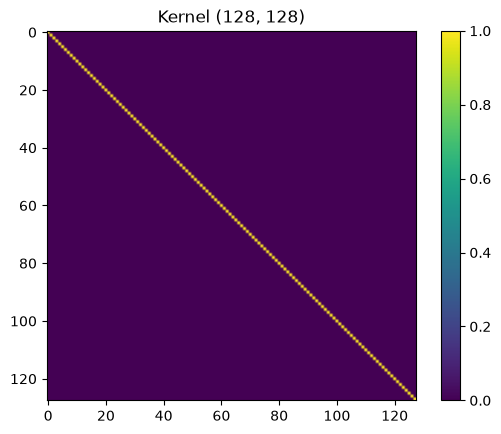

Epoch 1 - Loss 0.11170468229156598 - Fidelity 0.0181487778269337
Epoch 2 - Loss 0.0835357934729934 - Fidelity 0.041321459641135545
Epoch 3 - Loss 0.06512253162798504 - Fidelity 0.05861362430727938
Epoch 4 - Loss 0.056573007062076304 - Fidelity 0.06674750416024286
Epoch 5 - Loss 0.05166402365092171 - Fidelity 0.07426186562560043
Epoch 6 - Loss 0.04586760793000932 - Fidelity 0.08592747103254668
Epoch 7 - Loss 0.03904729530140723 - Fidelity 0.10243553392331735
Epoch 8 - Loss 0.03273809433040047 - Fidelity 0.12000572542376885
Epoch 9 - Loss 0.028126537578625686 - Fidelity 0.13339313760020569
Epoch 10 - Loss 0.025090535950348478 - Fidelity 0.14059705864254385
Epoch 11 - Loss 0.022451499338760596 - Fidelity 0.14734343195798297
Epoch 12 - Loss 0.01987670790196066 - Fidelity 0.15913623357829063
Epoch 13 - Loss 0.01770682571651733 - Fidelity 0.17922281081736932
Epoch 14 - Loss 0.01693005552456879 - Fidelity 0.21050858216731477
Epoch 15 - Loss 0.0196345151695965 - Fidelity 0.2527182912140939
Epo

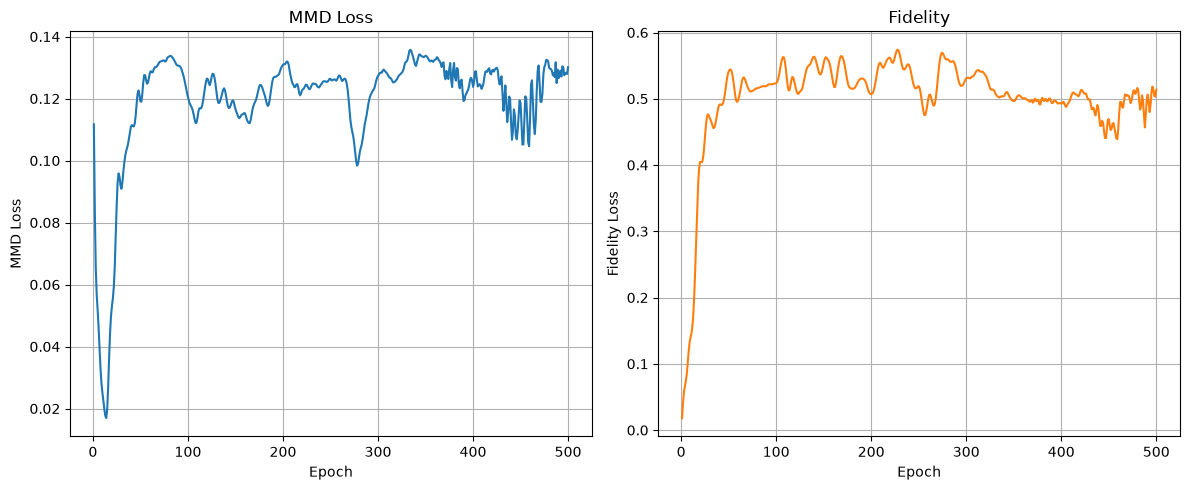


Training finished
Number of qubits: 7
Circuit depth (layers): 8
Number of parameters: 56
Final MMD loss: 0.57396974


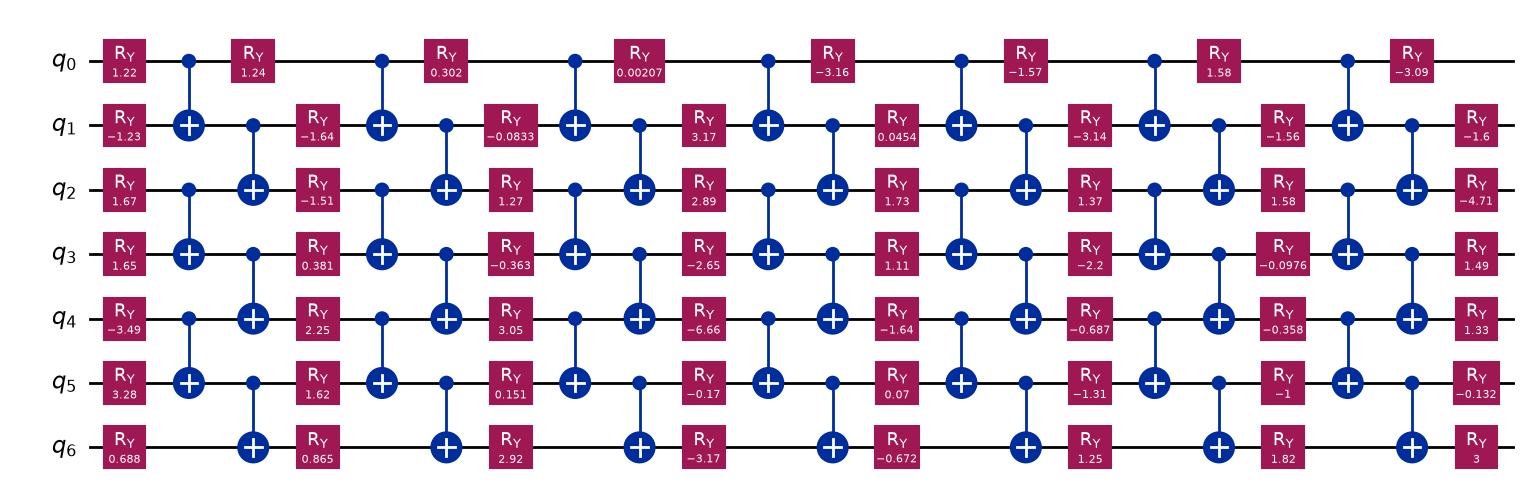


Data =  [[0 0 0 0]
 [1 0 0 0]
 [0 1 0 0]
 [1 1 0 0]
 [0 0 1 0]
 [1 0 1 0]
 [0 1 1 0]
 [1 1 1 0]
 [0 0 0 1]
 [1 0 0 1]
 [0 1 0 1]
 [1 1 0 1]
 [0 0 1 1]
 [1 0 1 1]
 [0 1 1 1]
 [1 1 1 1]]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.57396974


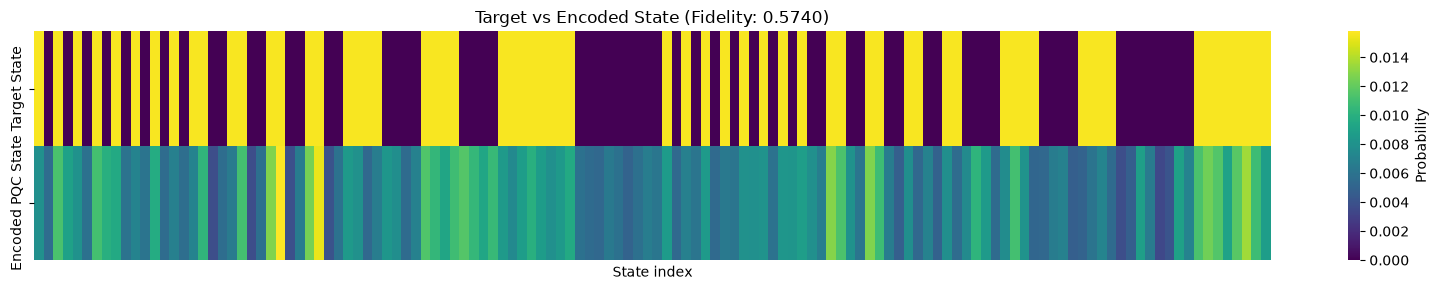

<Axes: title={'center': 'Target vs Encoded State (Fidelity: 0.5740)'}, xlabel='State index'>

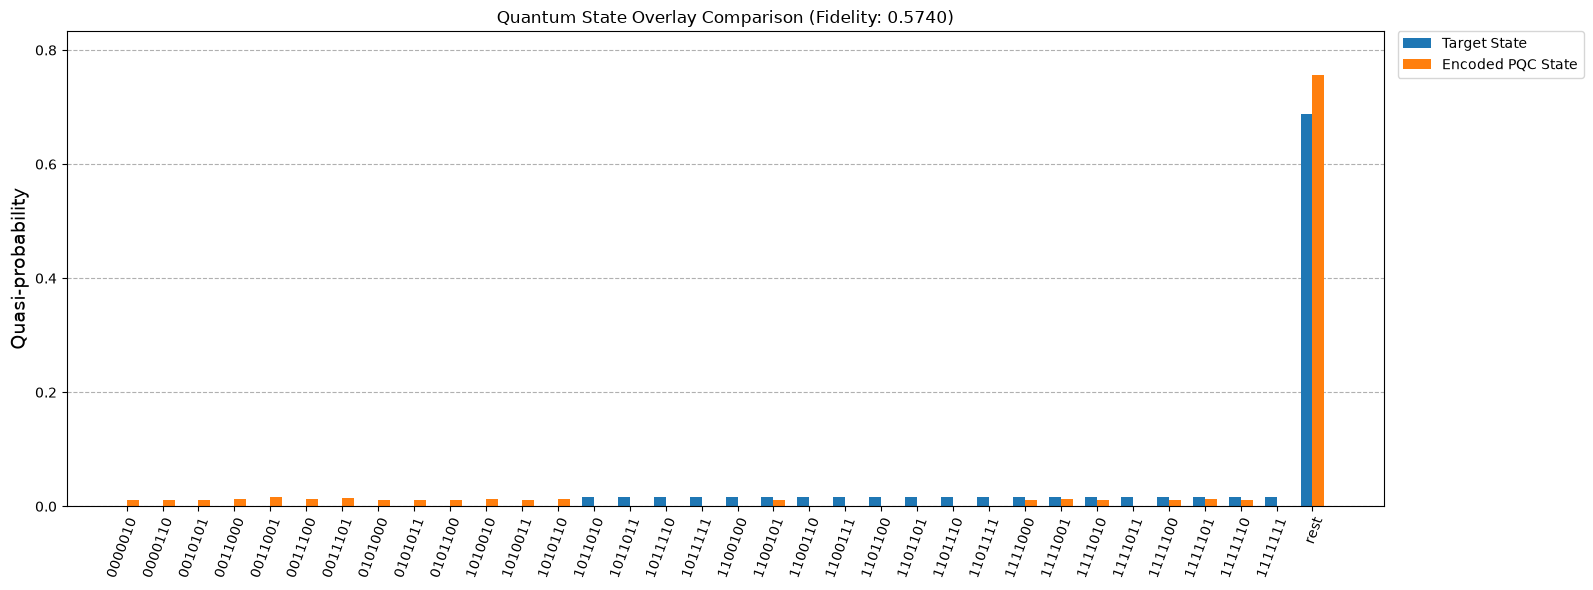

In [12]:
A_parameters_neqr_mmd = encoder.generate_encoding(dataset, scheme="NEQR", depth=8, epochs=500, learning_rate=0.1, loss_function_type="MMD")


Preparing query target state....

Number of feature qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 3
Total number of states (total_num_states): 8

Amplitude =  0.5

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 4

Number of parameters = 9


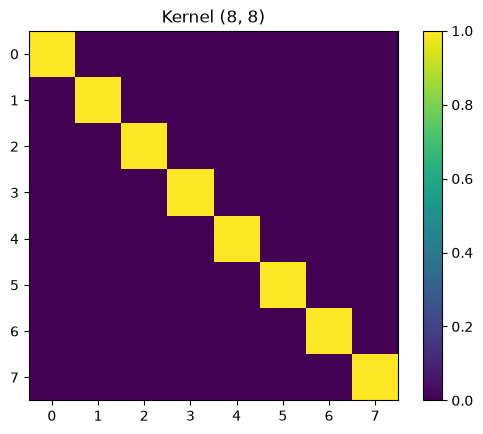

Epoch 1 - Loss 0.547021879587075 - Fidelity 0.04264386782160511
Epoch 2 - Loss 0.5432821452954364 - Fidelity 0.04494887286254582
Epoch 3 - Loss 0.5395328002444305 - Fidelity 0.04732499864805282
Epoch 4 - Loss 0.5357755267835134 - Fidelity 0.0497734080814157
Epoch 5 - Loss 0.5320120874316101 - Fidelity 0.05229529870971504
Epoch 6 - Loss 0.5282443219447013 - Fidelity 0.054891899893753975
Epoch 7 - Loss 0.5244741478704138 - Fidelity 0.05756446993720299
Epoch 8 - Loss 0.5207035624617785 - Fidelity 0.060314293138032445
Epoch 9 - Loss 0.5169346443472368 - Fidelity 0.06314267664119168
Epoch 10 - Loss 0.5131695536219045 - Fidelity 0.06605094687825587
Epoch 11 - Loss 0.5094105291244191 - Fidelity 0.0690404452716389
Epoch 12 - Loss 0.5056598816623291 - Fidelity 0.0721125227574347
Epoch 13 - Loss 0.5019199819076368 - Fidelity 0.0752685325481894
Epoch 14 - Loss 0.4981932416674019 - Fidelity 0.0785098204302044
Epoch 15 - Loss 0.49448208731693655 - Fidelity 0.08183771179606882
Epoch 16 - Loss 0.4907

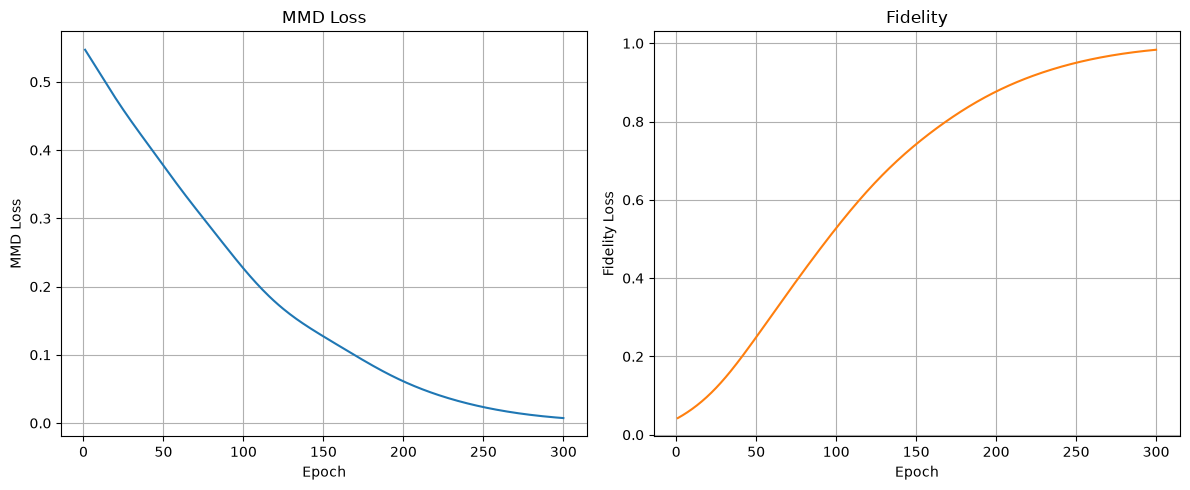


Training finished
Number of qubits: 3
Circuit depth (layers): 3
Number of parameters: 9
Final MMD loss: 0.98341533


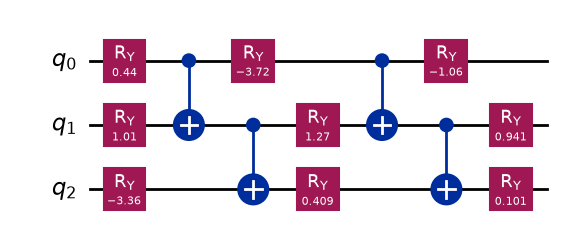


Data =  [1 1 0 0]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.98341533


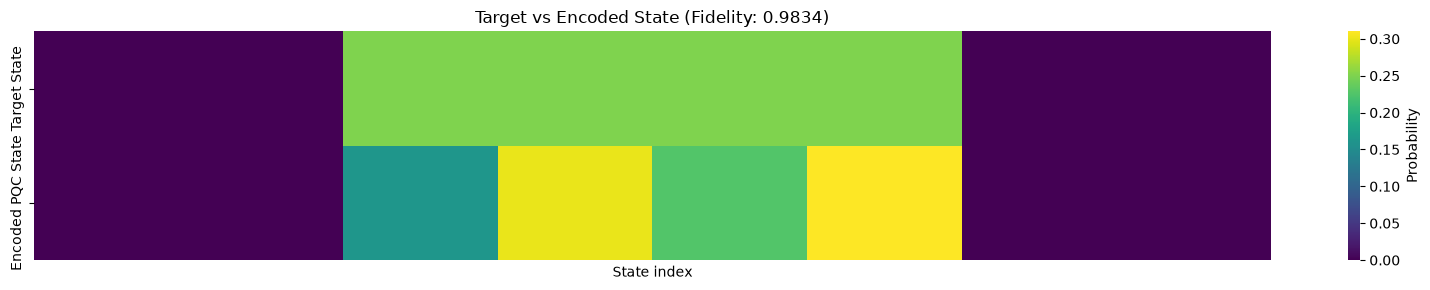

<Axes: title={'center': 'Target vs Encoded State (Fidelity: 0.9834)'}, xlabel='State index'>

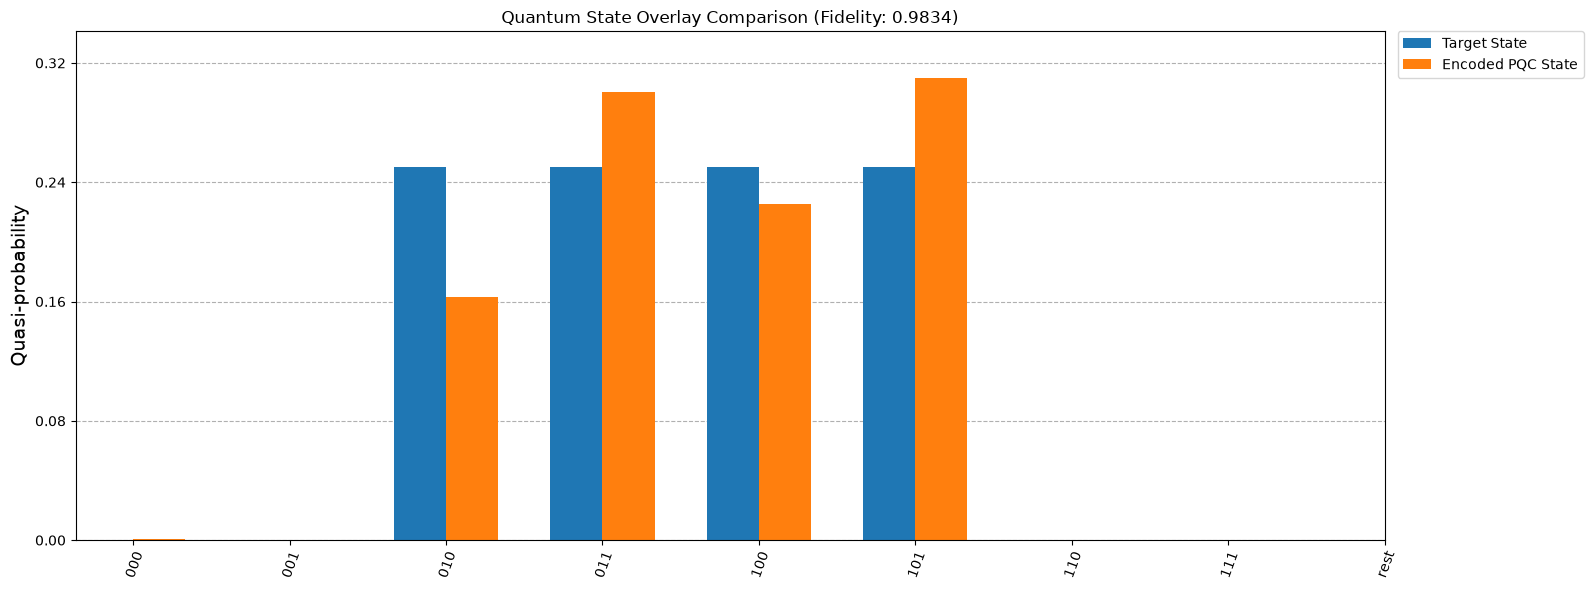

In [13]:
B_parameters_neqr_mmd = encoder.generate_encoding(query, scheme="NEQR", depth=3, epochs=300, learning_rate=0.005, loss_function_type="MMD")

## <u>**Encoding with NEQR scheme and FIDELITY cost function**</u>


Preparing dataset target state....

Num of data elements (N_I): 16
Num of features (N_D): 4
Number of index qubits (n_index_q): 4
Number of data qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 7
Total number of states:  128

Amplitude =  0.125

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 64

Number of parameters = 56
Epoch 1 - Loss 0.930631654295596 - Fidelity 0.06936834570440402
Epoch 2 - Loss 0.8590084282010843 - Fidelity 0.14099157179891578
Epoch 3 - Loss 0.8138142921617605 - Fidelity 0.18618570783823954
Epoch 4 - Loss 0.7561326221050461 - Fidelity 0.24386737789495397
Epoch 5 - Loss 0.6990926416995259 - Fidelity 0.3009073583004741
Epoch 6 - Loss 0.6510341068760941 - Fidelity 0.34896589312390597
Epoch 7 - Loss 0.5963457609862122 - Fidelity 0.4036542390137878
Epoch 8 - Loss 0.5345920518971385 - Fidelity 0.4654079481028614
Epoch 9 - Loss 0.4832447588200358 - Fidelity 0.5167552411799642
Epoch 10 - Loss 0.4569793699745295 - Fidelity 0.5430206300254705
Epoch 11 - Loss 0.4479139476870063 - Fidelity 0.5520860523129937
Epoch 12 - Loss 0.4367520644252403 - Fidelity 0.5632479355747597
Epoch 13 - Loss 0.41815355365096973 - Fidelity 0.5818464463490303
Epoch 14 - Loss 0.398731828909931 - Fidelity 0.601268171090069
Epoch 15 - Loss 0.3825414216

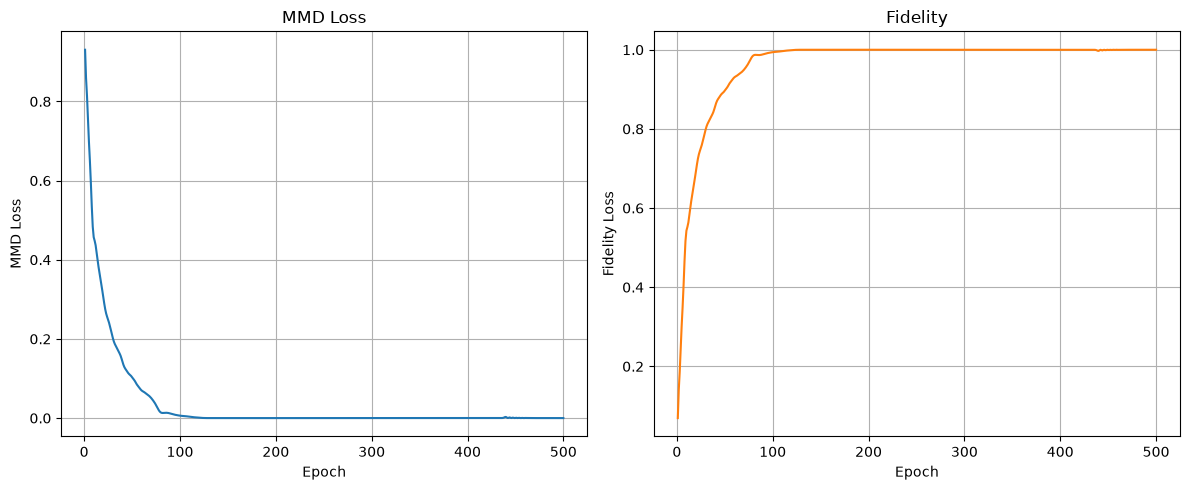


Training finished
Number of qubits: 7
Circuit depth (layers): 8
Number of parameters: 56
Final MMD loss: 0.99999946


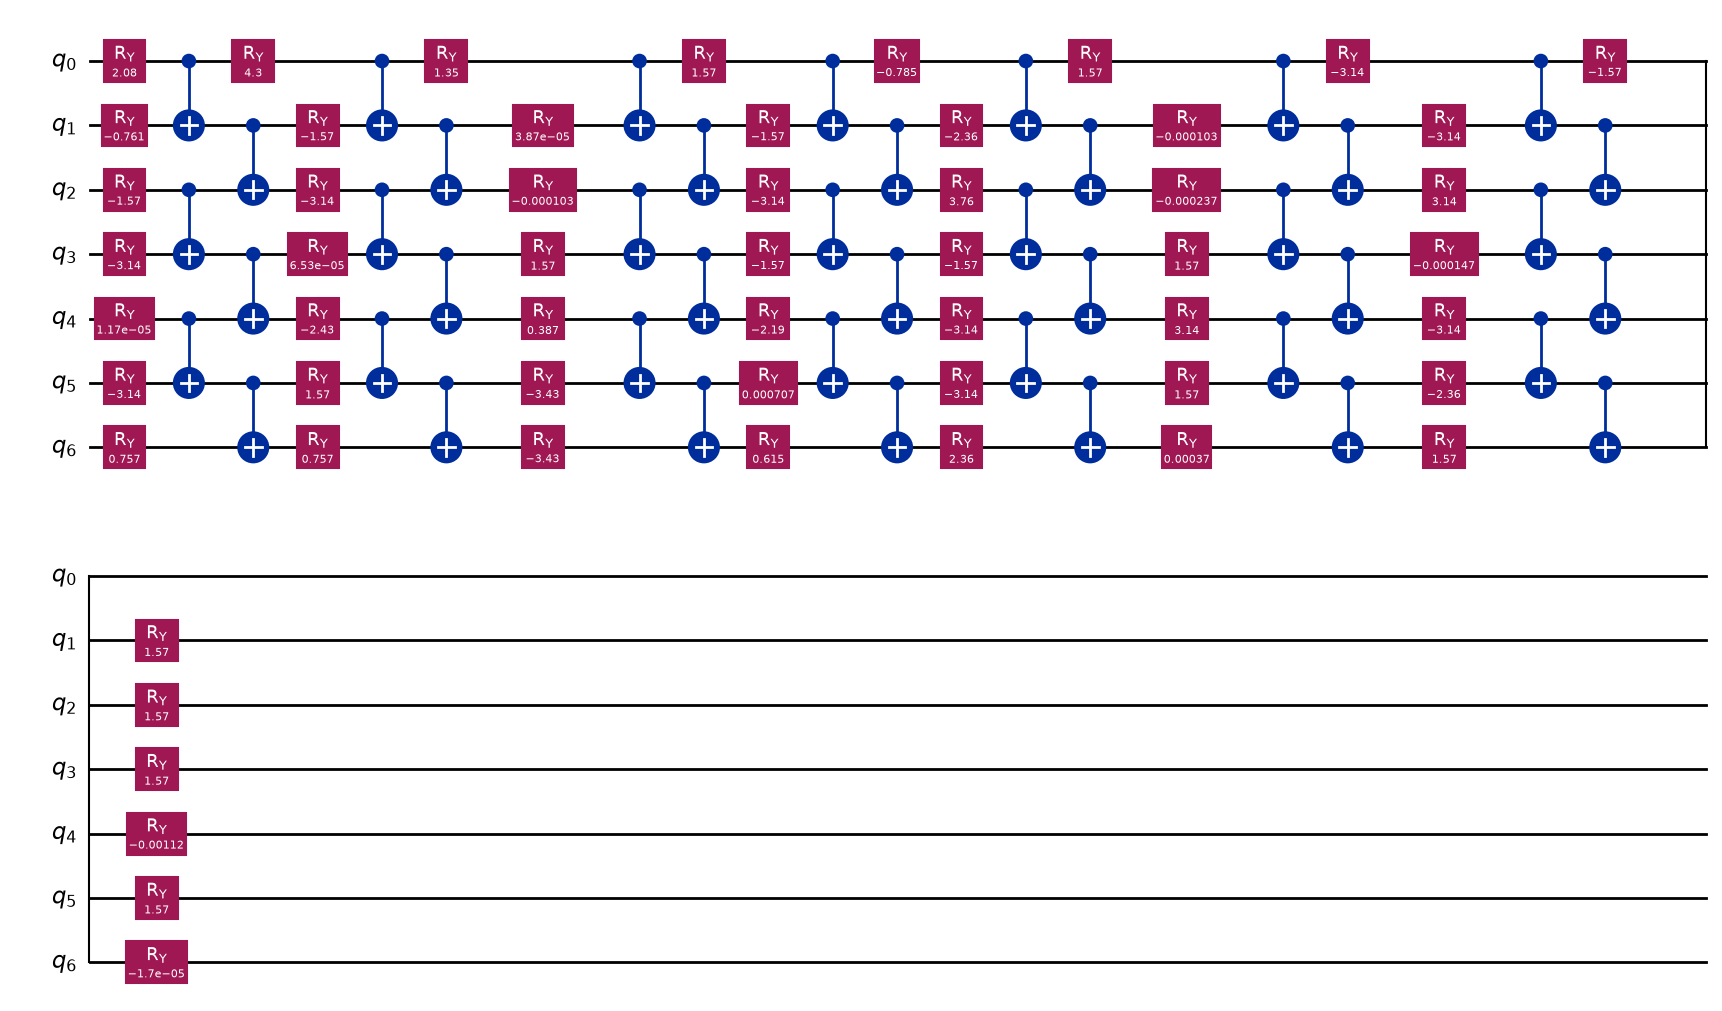


Data =  [[0 0 0 0]
 [1 0 0 0]
 [0 1 0 0]
 [1 1 0 0]
 [0 0 1 0]
 [1 0 1 0]
 [0 1 1 0]
 [1 1 1 0]
 [0 0 0 1]
 [1 0 0 1]
 [0 1 0 1]
 [1 1 0 1]
 [0 0 1 1]
 [1 0 1 1]
 [0 1 1 1]
 [1 1 1 1]]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.99999946


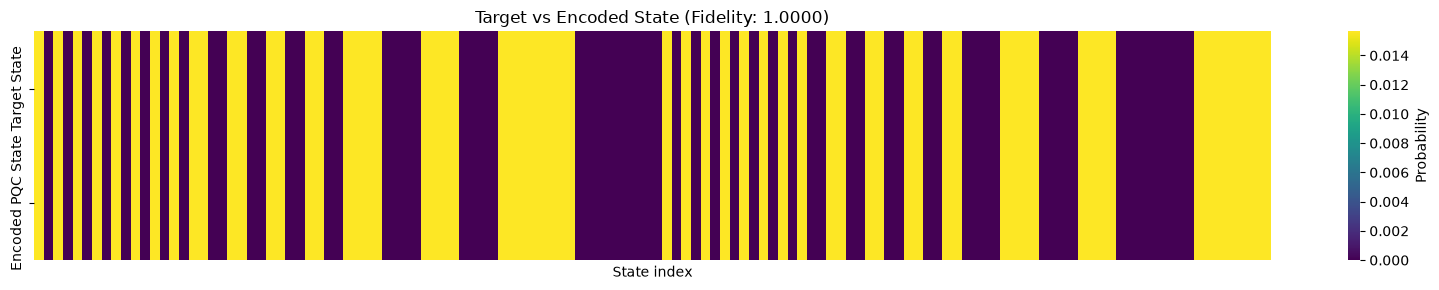

<Axes: title={'center': 'Target vs Encoded State (Fidelity: 1.0000)'}, xlabel='State index'>

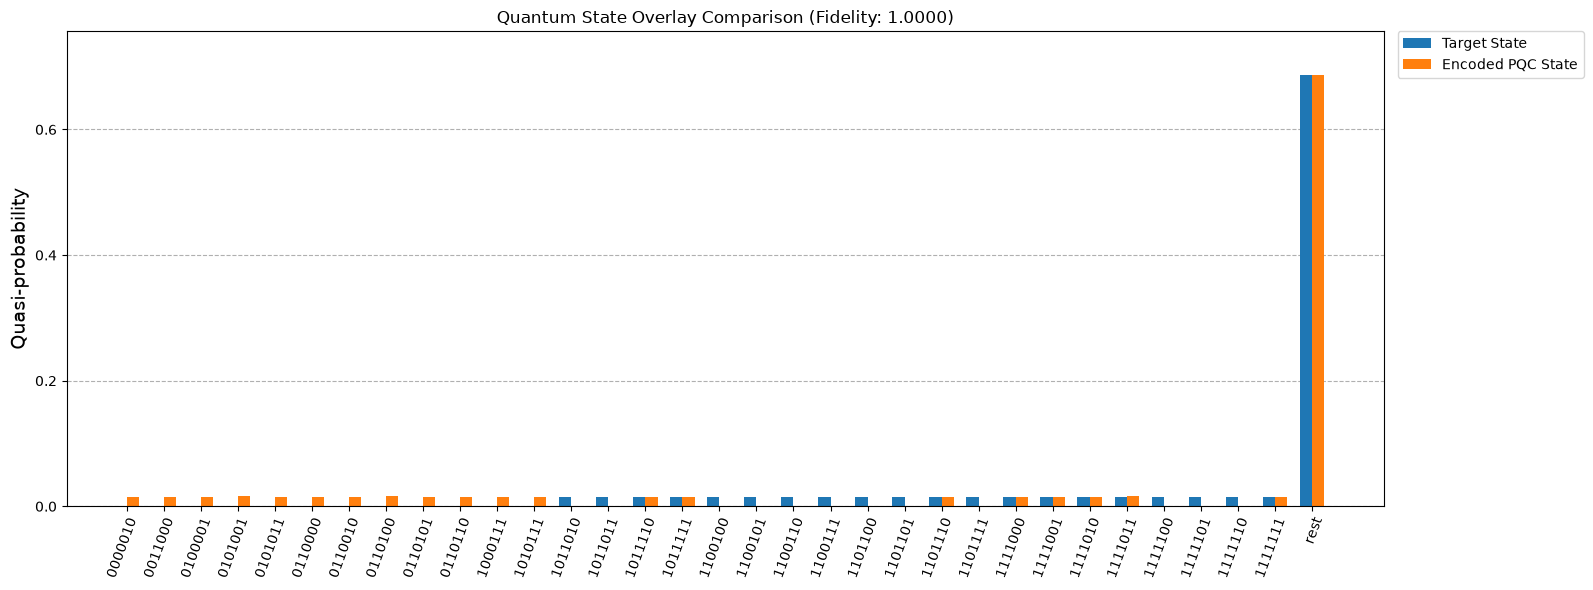

In [14]:
A_parameters_neqr_fidelity = encoder.generate_encoding(dataset, scheme="NEQR", depth=8, epochs=500, learning_rate=0.1, loss_function_type="FIDELITY")


Preparing query target state....

Number of feature qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 3
Total number of states (total_num_states): 8

Amplitude =  0.5

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 4

Number of parameters = 9
Epoch 1 - Loss 0.9940420358199717 - Fidelity 0.0059579641800282974
Epoch 2 - Loss 0.9924899311481139 - Fidelity 0.007510068851886124
Epoch 3 - Loss 0.9907551504165365 - Fidelity 0.009244849583463504
Epoch 4 - Loss 0.9888352639863363 - Fidelity 0.011164736013663735
Epoch 5 - Loss 0.9867274451618209 - Fidelity 0.013272554838179108
Epoch 6 - Loss 0.9844285681529535 - Fidelity 0.015571431847046466
Epoch 7 - Loss 0.9819352979486733 - Fidelity 0.018064702051326733
Epoch 8 - Loss 0.9792441717880828 - Fidelity 0.020755828211917196
Epoch 9 - Loss 0.9763516729620954 - Fidelity 0.02364832703790467
Epoch 10 - Loss 0.9732542979943056 - Fidelity 0.02674570200569436
Epoch 11 - Loss 0.9699486182398392 - Fidelity 0.030051381760160756
Epoch 12 - Loss 0.9664313368009061 - Fidelity 0.03356866319909385
Epoch 13 - Loss 0.9626993414799624 - Fidelity 0.037300658520037576
Epoch 14 - Loss 0.9587497543166569 - Fidelity 0.04125024568334315
Epoch 15

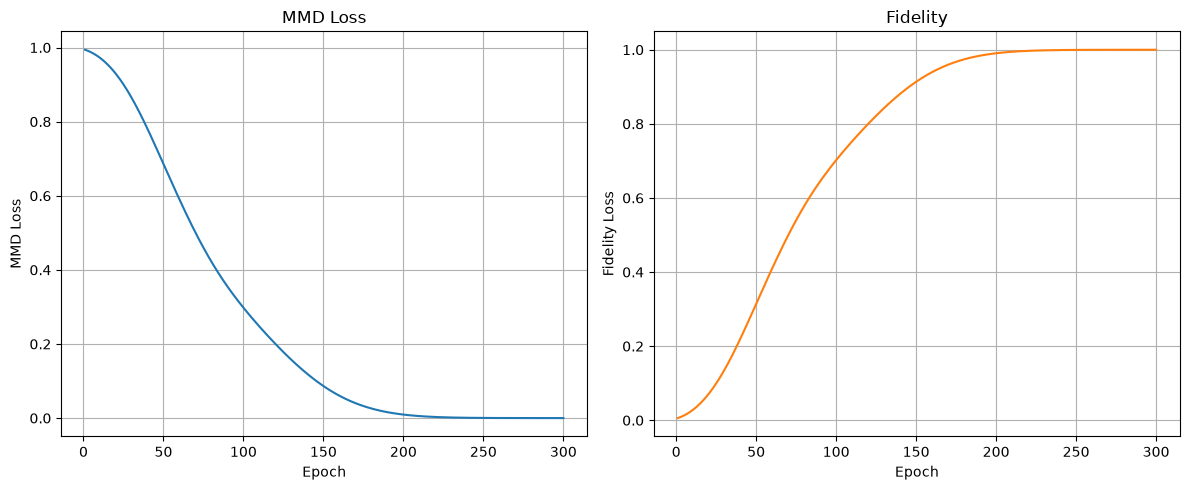


Training finished
Number of qubits: 3
Circuit depth (layers): 3
Number of parameters: 9
Final MMD loss: 0.99995891


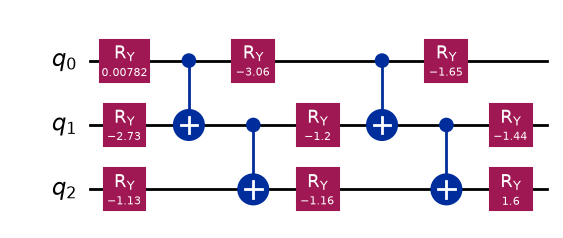


Data =  [1 1 0 0]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.99995891


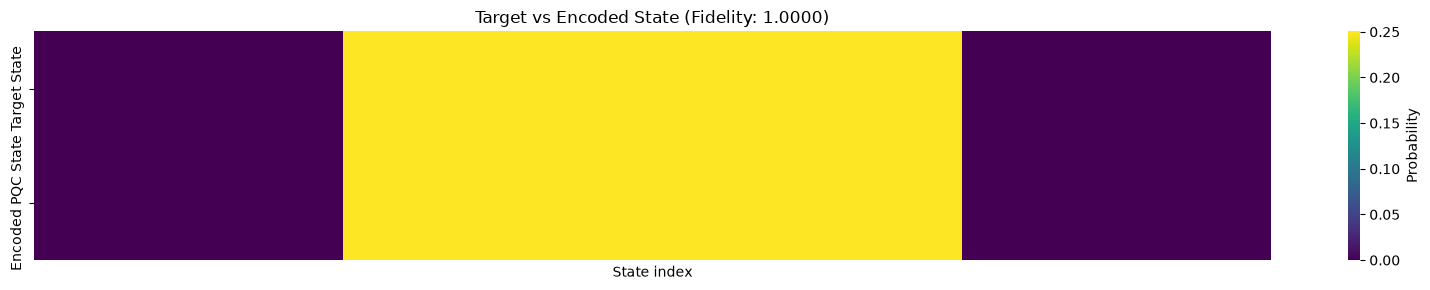

<Axes: title={'center': 'Target vs Encoded State (Fidelity: 1.0000)'}, xlabel='State index'>

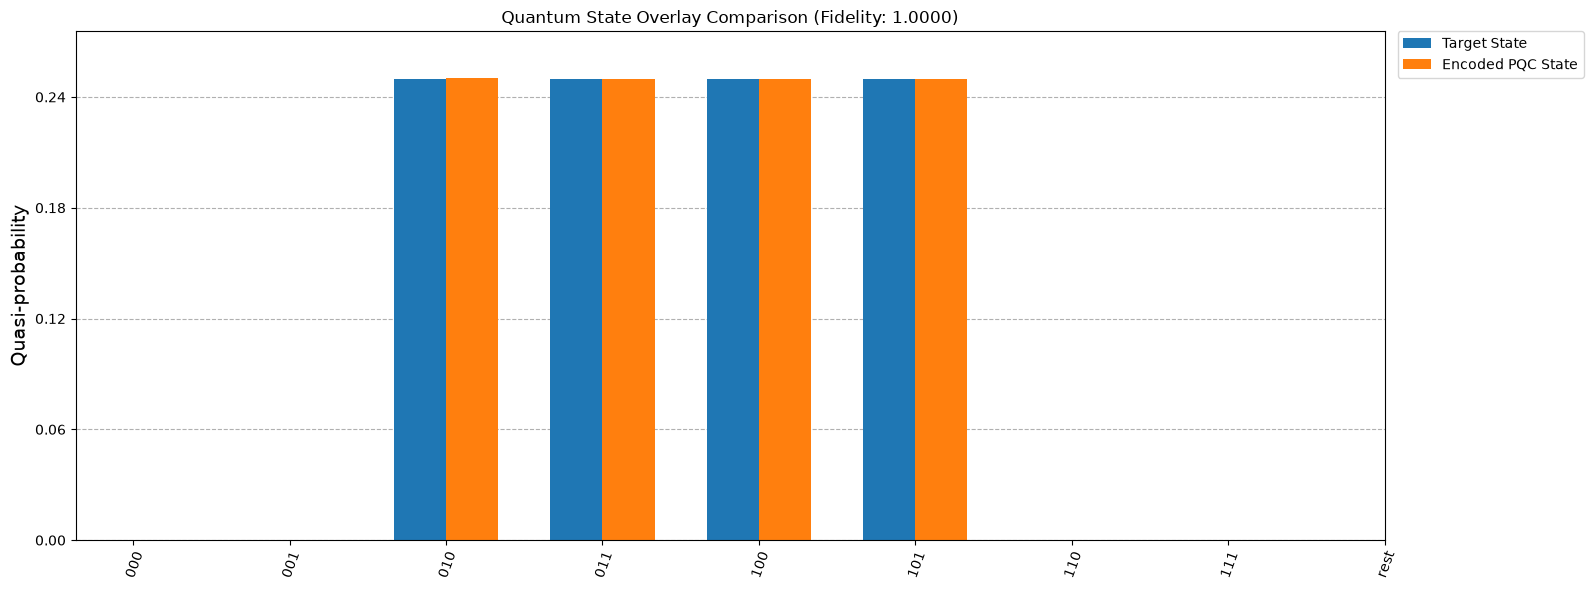

In [15]:
B_parameters_neqr_fidelity = encoder.generate_encoding(query, scheme="NEQR", depth=3, epochs=300, learning_rate=0.005, loss_function_type="FIDELITY")

# <u>**Part 2: Use Grover Search for Image Matching**</u>

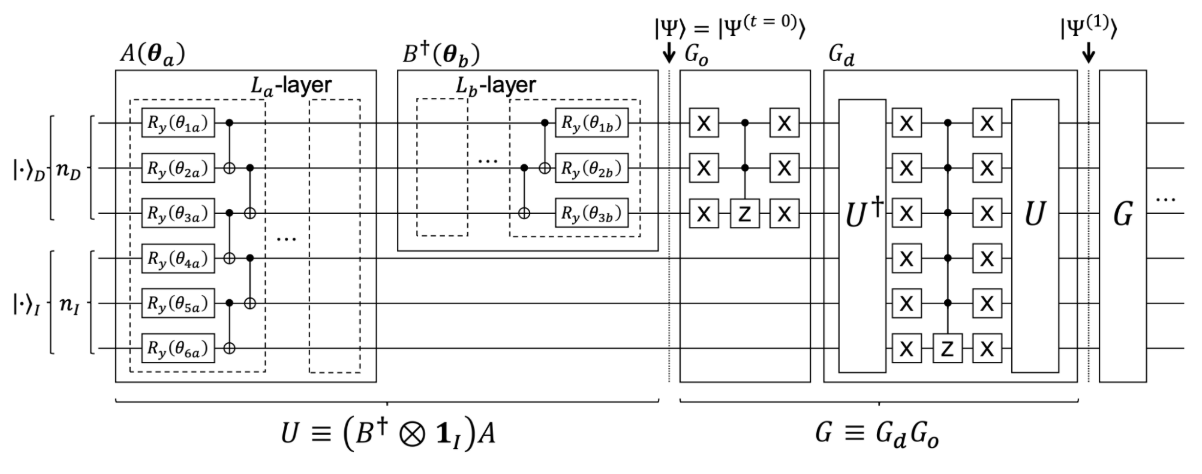

In [16]:
class GroverSearch:
  def pqc(self, parameters, depth, n_qubits):
    qc = QuantumCircuit(n_qubits)
    t = 0

    for _ in range(depth):
        # rotation layer
        for q in range(n_qubits):
            qc.ry(parameters[t], q)
            t += 1

        # entangling layer
        for q in range(n_qubits - 1):
            qc.cx(q, q + 1)

    return qc

  def build_U(self):
    # U = (B† ⊗ I_I) A
    # Qubit order: |data>|index>
    # A encodes the database, B† acts on data qubits only

    qc = QuantumCircuit(self.total_qubits)

    A = self.pqc(self.A_parameters, self.depth_A, self.total_qubits)
    B = self.pqc(self.B_parameters, self.depth_B, self.n_data_q)

    qc.compose(A, qubits=list(range(self.total_qubits)), inplace=True)
    qc.barrier()

    qc.compose(B.inverse(), qubits=self.data_q, inplace=True)
    qc.barrier()

    return qc

  def phase_flip_zero(self, qc, qubits):
    # Phase flip of |00...0> 
    # X gates convert |00...0> into |11...1>
    # H-MCX-H implements the multi-controlled Z operation to flip the phase of |11...1>

    if len(qubits) == 1:
        qc.x(qubits[0])
        qc.z(qubits[0])
        qc.x(qubits[0])

    else:
        qc.x(qubits)

        qc.h(qubits[-1])
        qc.mcx(qubits[:-1], qubits[-1])
        qc.h(qubits[-1])

        qc.x(qubits)

    return qc

  def oracle(self): # inversion-test oracle Go
    # Go phase-flips the all-zero data state after B†
    # This makes the phase depend on the query-data overlap

    qc = QuantumCircuit(self.total_qubits)

    self.phase_flip_zero(qc, self.data_q)
    qc.barrier()

    return qc

  def diffuser(self): # Gd = U† (phase flip of zero on all qubits) U
    # implements reflection about U|0>

    qc = QuantumCircuit(self.total_qubits)

    U = self.build_U()

    qc.compose(U.inverse(), qubits=list(range(self.total_qubits)), inplace=True)
    qc.barrier()

    self.phase_flip_zero(qc, list(range(self.total_qubits)))
    qc.barrier()

    qc.compose(U, qubits=list(range(self.total_qubits)), inplace=True)
    qc.barrier()

    return qc

  def visualize(self, qc, text):
    no_of_locators_on_chart = 10

    state = Statevector.from_instruction(qc)
    probs_dict = state.probabilities_dict(qargs=self.index_q)
    probs_dict = {int(k, 2): v for k, v in probs_dict.items()} # convert binary string keys to integers for better readability
    print(f"{text}: ", probs_dict)

    plot = plot_distribution(probs_dict, bar_labels=False)
    plot.axes[0].xaxis.set_major_locator(plt.MaxNLocator(no_of_locators_on_chart))

    display(plot)

  def run(self, dataset, query,
      A_parameters, B_parameters, depth_A=6, depth_B=3,
      num_of_iter=1, no_of_shots=2000
  ):
    # Dataset and query dimensions
    self.N_I = len(dataset)
    self.N_D = len(dataset[0])
    self.N_Q = len(query)

    # Number of index qubits
    self.n_index_q = math.ceil(math.log2(self.N_I))

    # Number of pixel-position qubits
    self.n_pixel_q = math.ceil(math.log2(self.N_D))

    # Use one consistent intensity range for the database and query.
    # For values 0..255, this gives 8 intensity qubits.
    max_value = max(int(np.max(dataset)), int(np.max(query)))
    self.n_value_q = max(1, math.ceil(math.log2(max_value + 1)))

    # The data register includes pixel-position AND intensity qubits.
    self.n_data_q = self.n_pixel_q + self.n_value_q

    # Total qubits = data register + image-index register
    self.total_qubits = self.n_index_q + self.n_data_q

    # Match the basis-state indexing used in prepare_neqr_dataset_target:
    # index bits are the least-significant bits.
    self.index_q = list(range(self.n_index_q))

    # B† acts on the entire data register, not just pixel-position qubits.
    self.data_q = list(range(self.n_index_q, self.total_qubits))

    # Keep the number of image-index states separate from the
    # dimension of the data register.
    self.padded_N_I = 2**self.n_index_q
    self.padded_N_P = 2**self.n_pixel_q

    print("Index qubits:", self.index_q)
    print("Data qubits:", self.data_q)
    print("Pixel-position qubits:", self.n_pixel_q)
    print("Intensity qubits:", self.n_value_q)
    print("Total qubits:", self.total_qubits)

    # pad the dataset and query to the power of 2

    padded_dataset = np.zeros((self.padded_N_I, self.padded_N_P))
    padded_dataset[:self.N_I, :self.N_D] = dataset
    dataset = padded_dataset

    padded_query = np.zeros(self.padded_N_P)
    padded_query[:self.N_Q] = query 
    query = padded_query

    # A and B parameters

    self.A_parameters = np.asarray(A_parameters)
    self.B_parameters = np.asarray(B_parameters)
    self.depth_A = depth_A
    self.depth_B = depth_B

    print("N = ", self.N_I)
    print("Index qubits = ", self.index_q)
    print("Data qubits = ", self.data_q)
    print("Total no of qubits = ", self.total_qubits)

    # num_of_iter = max(1, round(((math.pi / 4) * math.sqrt(self.N_I)) - 0.5))
    # print("\nGrover iterations: ", num_of_iter)

    index_qubits = QuantumRegister(self.n_index_q, name="index")
    data_qubits = QuantumRegister(self.n_data_q, name="data")
    value_qubits = QuantumRegister(self.n_value_q, name="value")
    qc = QuantumCircuit(index_qubits, data_qubits, value_qubits)
    
    qc = self.build_U()
    self.visualize(qc, "Encoded state U|Psi(0)>")

    for iteration in range(num_of_iter):
        print(f"\nGROVER ITERATION {iteration + 1}")

        print("\nOracle: ")
        oracle_circuit = self.oracle()
        qc.compose(oracle_circuit, qubits=list(range(self.total_qubits)), inplace=True)
        self.visualize(qc, "Oracle output")

        print("\nDiffuser: ")
        diffuser_circuit = self.diffuser()
        qc.compose(diffuser_circuit, qubits=list(range(self.total_qubits)), inplace=True)
        self.visualize(qc, "Diffuser output")

    print("\nFINAL MEASUREMENT")

    self.qc = qc.copy()

    classical_register = ClassicalRegister(self.n_index_q, name="index_result")
    self.qc.add_register(classical_register)

    self.qc.measure(self.index_q, classical_register)

    simulator = AerSimulator()
    compiled = transpile(self.qc, simulator)

    result = simulator.run(compiled, shots=no_of_shots).result()
    counts = result.get_counts()

    print(f"\nIndex measurement results for ({no_of_shots}) shots:")
    print(counts)

    self.qc = qc.copy()

  def draw_circuit(self):
    display(self.qc.draw("mpl"))

  def analysis(self):
    print("REGISTER ANALYSIS")

    print("Dataset size (N):", self.N_I)
    print("Index qubits:", len(self.index_q))
    print("Data qubits:", len(self.data_q))
    print("Total qubits:", self.qc.num_qubits)
    print("Classical bits:", self.qc.num_clbits)

    print("\nCIRCUIT ANALYSIS")

    print("Circuit width:", self.qc.width())
    print("Circuit size:", self.qc.size())
    print("Circuit depth/layers:", self.qc.depth())

    print("\nOPERATION COUNT")
    print(self.qc.count_ops())

  
  def visualize(self, qc, text):
    no_of_locators_on_chart = 10

    state = Statevector.from_instruction(qc)

    # Display the complete quantum state in LaTeX notation
    print(f"\n{text} - Quantum State:")
    display(state.draw('latex'))

    probs_dict = state.probabilities_dict(qargs=self.index_q)
    probs_dict = {int(k, 2): v for k, v in probs_dict.items()} # convert binary string keys to integers for better readability

    plot = plot_distribution(probs_dict, bar_labels=False)
    plot.axes[0].xaxis.set_major_locator(plt.MaxNLocator(no_of_locators_on_chart))

    display(plot)


In [17]:
GS = GroverSearch()

## <u>**GS with NEQR scheme and MMD cost function**</u>

Index qubits: [0, 1, 2, 3]
Data qubits: [4, 5, 6]
Pixel-position qubits: 2
Intensity qubits: 1
Total qubits: 7
N =  16
Index qubits =  [0, 1, 2, 3]
Data qubits =  [4, 5, 6]
Total no of qubits =  7

Encoded state U|Psi(0)> - Quantum State:


<IPython.core.display.Latex object>

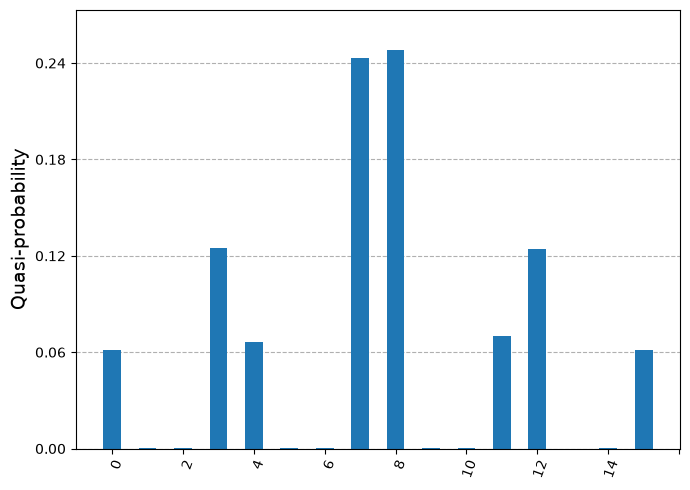


GROVER ITERATION 1

Oracle: 

Oracle output - Quantum State:


<IPython.core.display.Latex object>

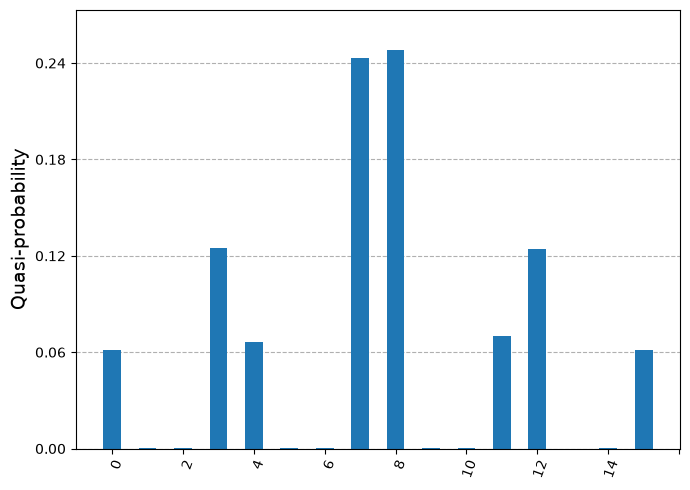


Diffuser: 

Diffuser output - Quantum State:


<IPython.core.display.Latex object>

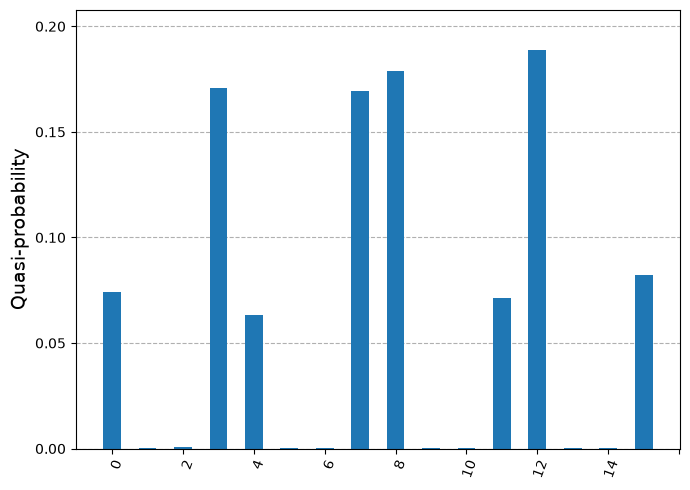


GROVER ITERATION 2

Oracle: 

Oracle output - Quantum State:


<IPython.core.display.Latex object>

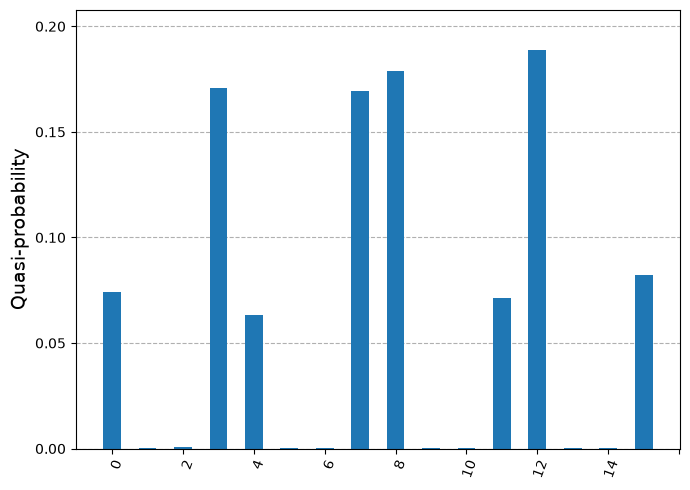


Diffuser: 

Diffuser output - Quantum State:


<IPython.core.display.Latex object>

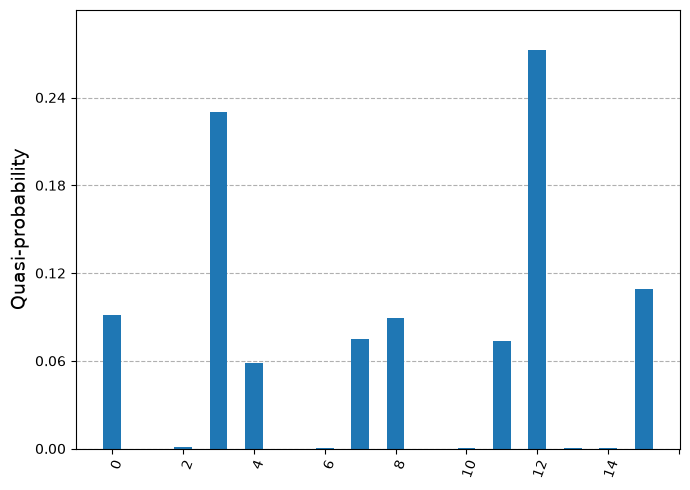


GROVER ITERATION 3

Oracle: 

Oracle output - Quantum State:


<IPython.core.display.Latex object>

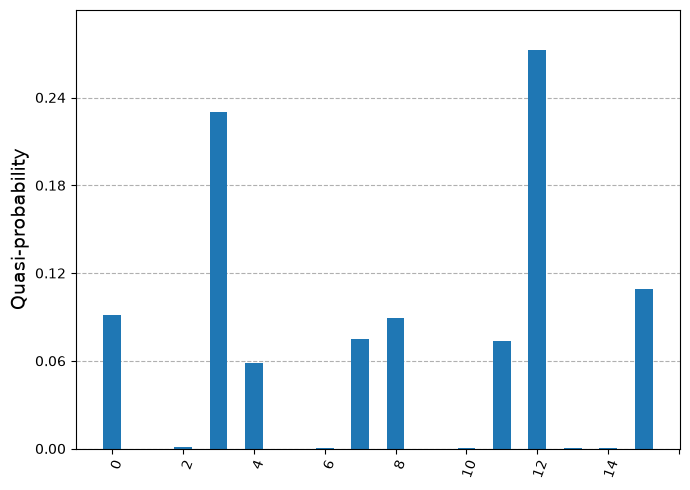


Diffuser: 

Diffuser output - Quantum State:


<IPython.core.display.Latex object>

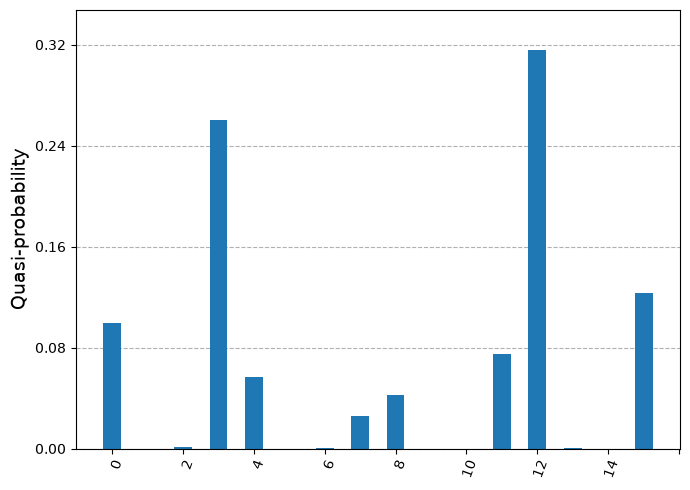


GROVER ITERATION 4

Oracle: 

Oracle output - Quantum State:


<IPython.core.display.Latex object>

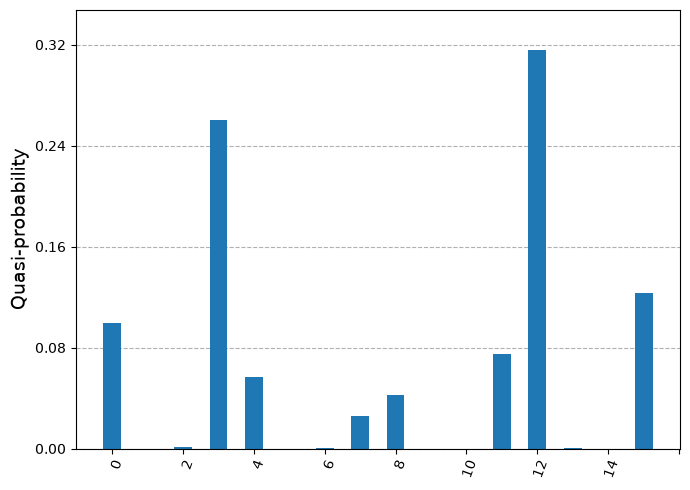


Diffuser: 

Diffuser output - Quantum State:


<IPython.core.display.Latex object>

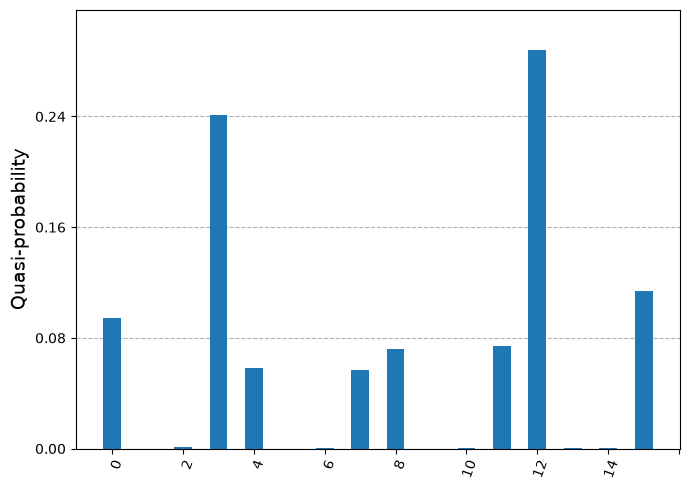


GROVER ITERATION 5

Oracle: 

Oracle output - Quantum State:


<IPython.core.display.Latex object>

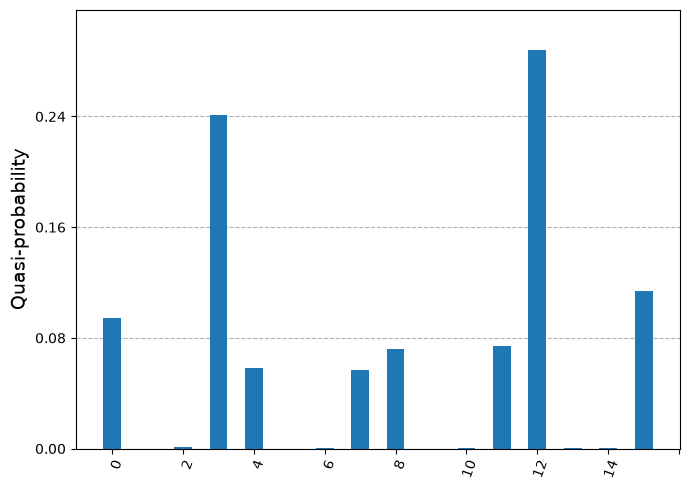


Diffuser: 

Diffuser output - Quantum State:


<IPython.core.display.Latex object>

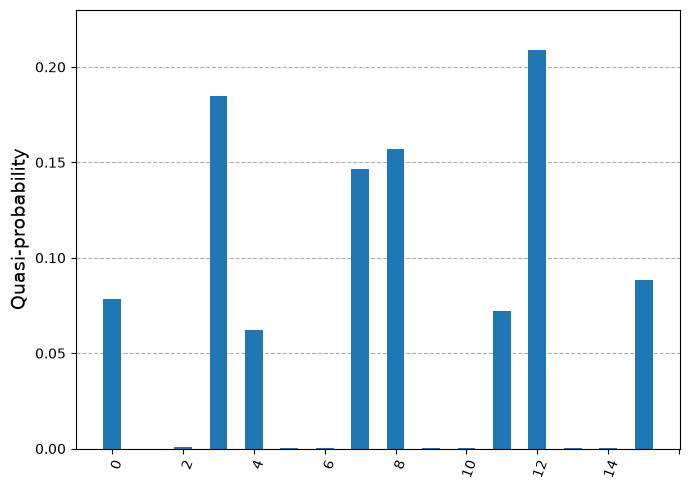


FINAL MEASUREMENT

Index measurement results for (2000) shots:
{'1010': 1, '1001': 1, '0101': 1, '0011': 362, '0001': 1, '1100': 428, '0100': 129, '0010': 1, '0000': 162, '1110': 1, '1000': 303, '0111': 282, '1111': 184, '1011': 144}


In [18]:
GS.run(dataset=dataset, query=query,
    A_parameters=A_parameters_neqr_mmd, B_parameters=B_parameters_neqr_mmd,
    depth_A=6, depth_B=3,
    num_of_iter=5
)

In [19]:
query_index

3

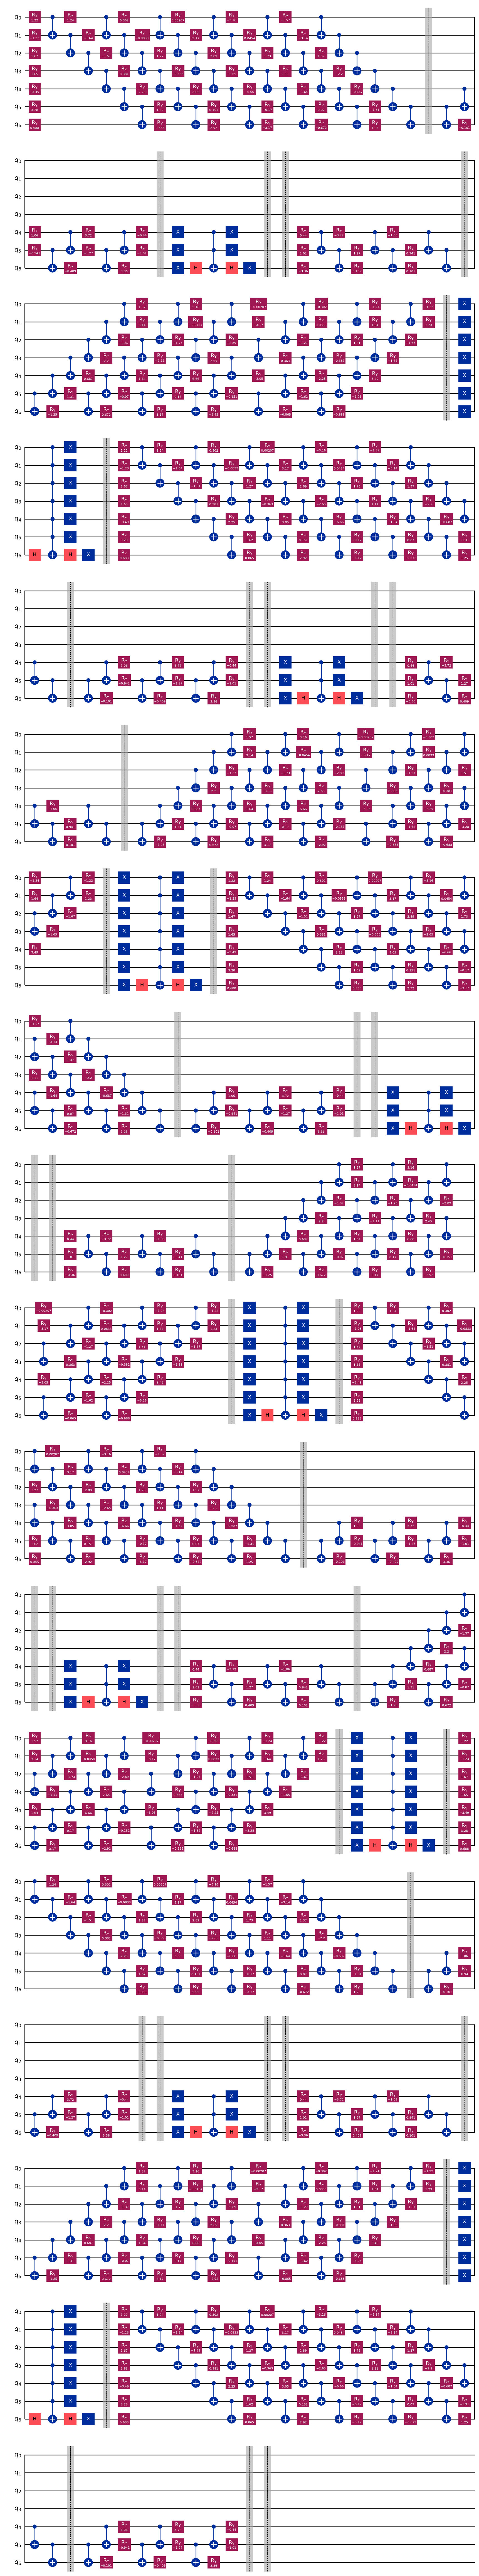

In [20]:
GS.draw_circuit()

In [21]:
GS.analysis()

REGISTER ANALYSIS
Dataset size (N): 16
Index qubits: 4
Data qubits: 3
Total qubits: 7
Classical bits: 0

CIRCUIT ANALYSIS
Circuit width: 7
Circuit size: 1153
Circuit depth/layers: 391

OPERATION COUNT
OrderedDict({'ry': 561, 'cx': 462, 'x': 100, 'barrier': 42, 'h': 20, 'ccx': 5, 'mcx': 5})


## <u>**GS with NEQR scheme and FIDELITY cost function**</u>

Index qubits: [0, 1, 2, 3]
Data qubits: [4, 5, 6]
Pixel-position qubits: 2
Intensity qubits: 1
Total qubits: 7
N =  16
Index qubits =  [0, 1, 2, 3]
Data qubits =  [4, 5, 6]
Total no of qubits =  7

Encoded state U|Psi(0)> - Quantum State:


<IPython.core.display.Latex object>

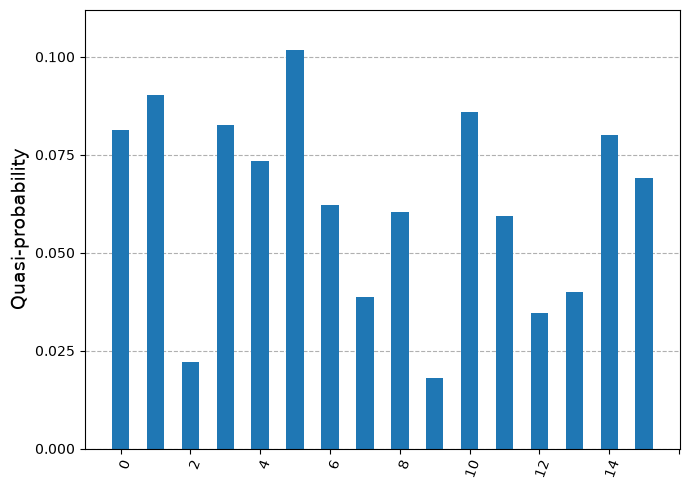


GROVER ITERATION 1

Oracle: 

Oracle output - Quantum State:


<IPython.core.display.Latex object>

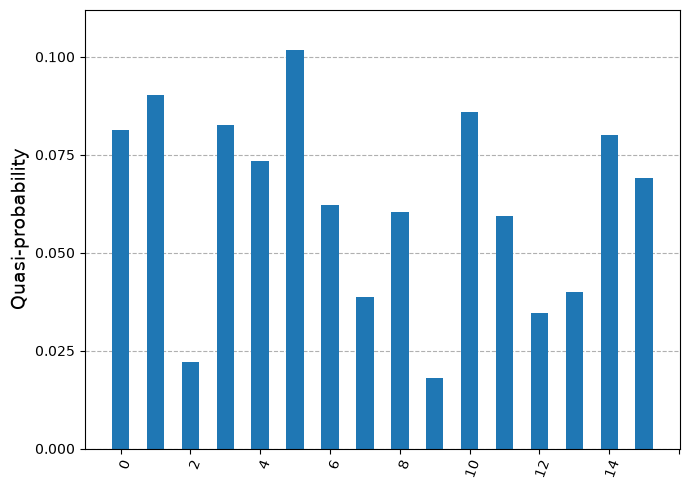


Diffuser: 

Diffuser output - Quantum State:


<IPython.core.display.Latex object>

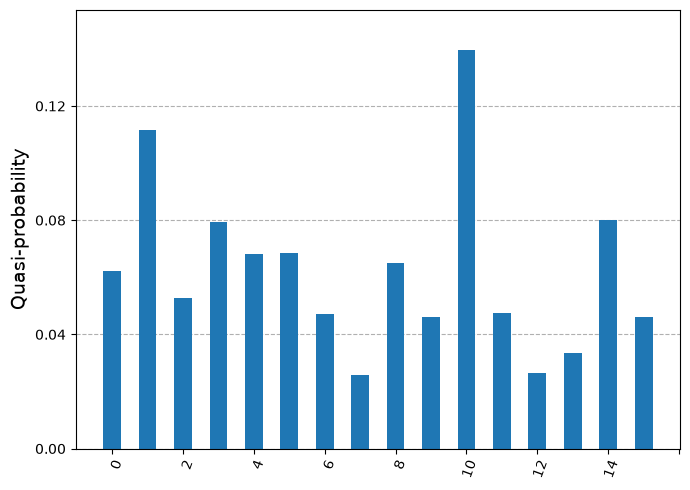


GROVER ITERATION 2

Oracle: 

Oracle output - Quantum State:


<IPython.core.display.Latex object>

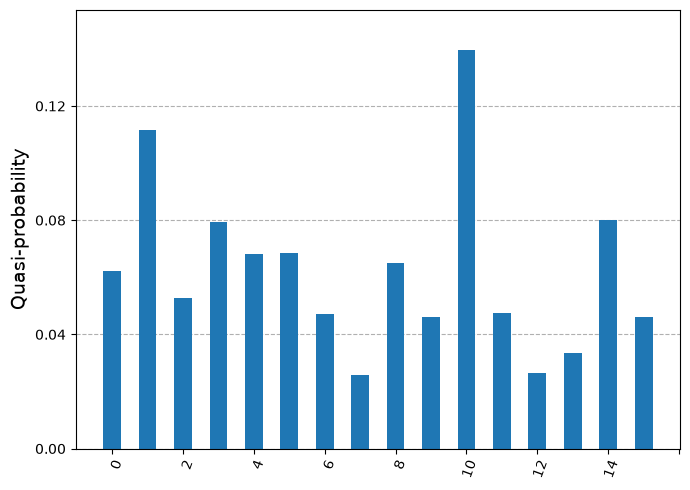


Diffuser: 

Diffuser output - Quantum State:


<IPython.core.display.Latex object>

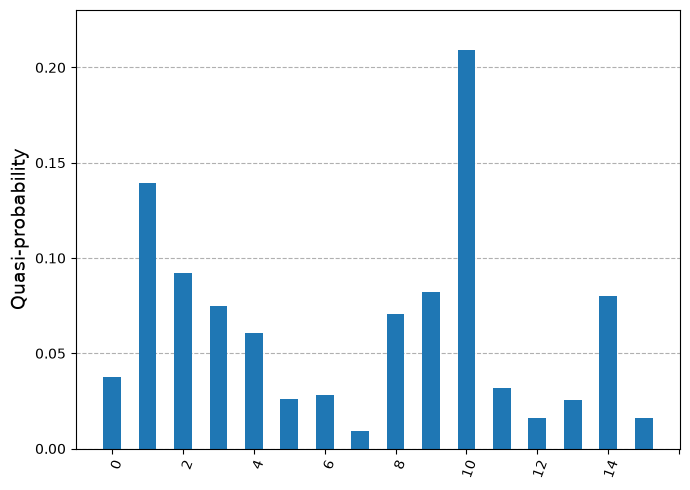


GROVER ITERATION 3

Oracle: 

Oracle output - Quantum State:


<IPython.core.display.Latex object>

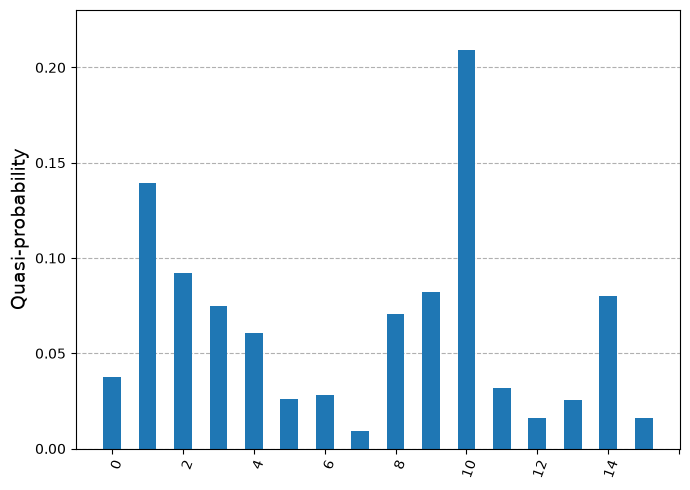


Diffuser: 

Diffuser output - Quantum State:


<IPython.core.display.Latex object>

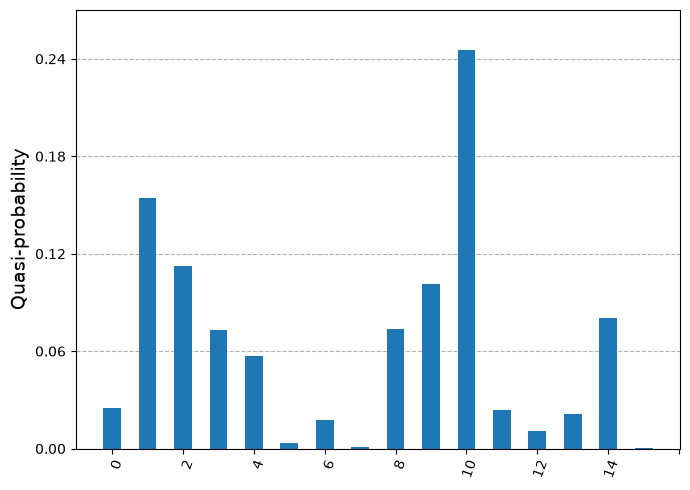


GROVER ITERATION 4

Oracle: 

Oracle output - Quantum State:


<IPython.core.display.Latex object>

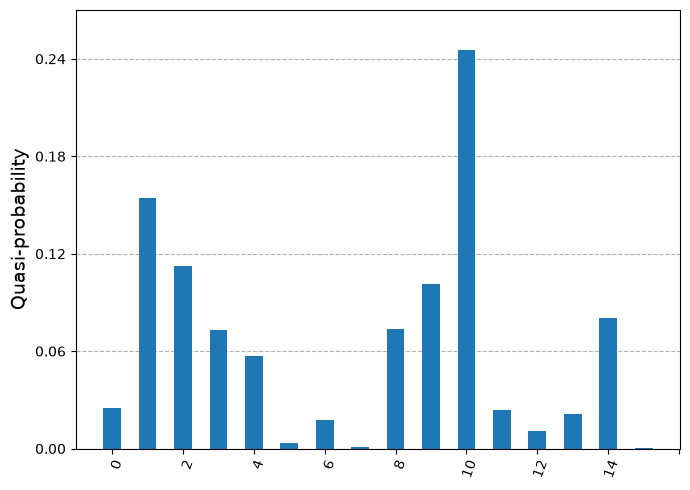


Diffuser: 

Diffuser output - Quantum State:


<IPython.core.display.Latex object>

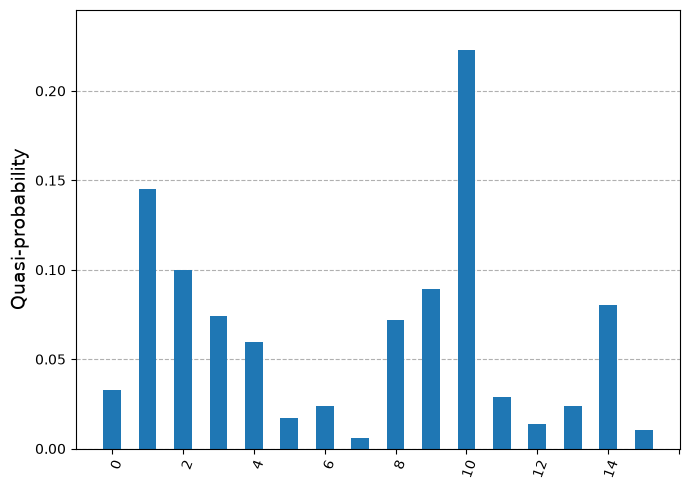


GROVER ITERATION 5

Oracle: 

Oracle output - Quantum State:


<IPython.core.display.Latex object>

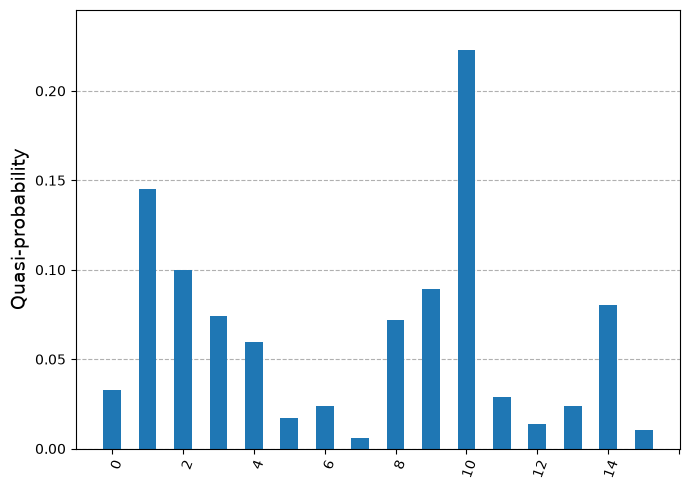


Diffuser: 

Diffuser output - Quantum State:


<IPython.core.display.Latex object>

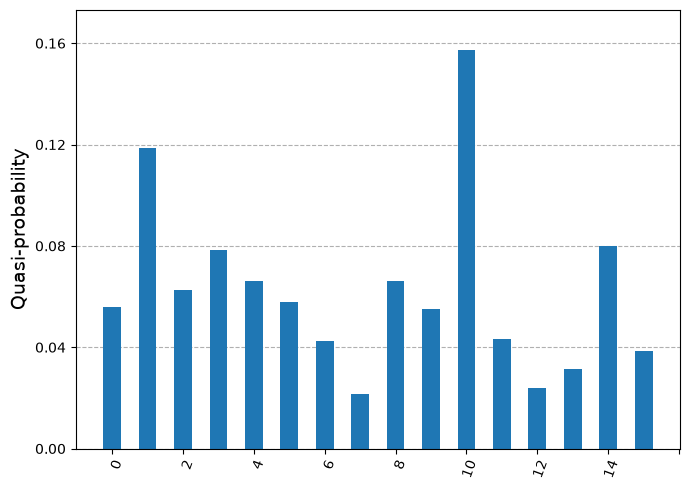


FINAL MEASUREMENT

Index measurement results for (2000) shots:
{'0000': 121, '0011': 149, '0001': 238, '1011': 88, '1001': 117, '0111': 48, '1101': 49, '1111': 76, '0101': 121, '1000': 132, '0100': 126, '1100': 46, '1110': 175, '0110': 76, '0010': 138, '1010': 300}


In [22]:
GS.run(dataset=dataset, query=query,
    A_parameters=A_parameters_neqr_fidelity, B_parameters=B_parameters_neqr_fidelity,
    depth_A=6, depth_B=3,
    num_of_iter=5
)



In [23]:
GS.draw_circuit()

In [24]:
GS.analysis()

REGISTER ANALYSIS
Dataset size (N): 16
Index qubits: 4
Data qubits: 3
Total qubits: 7
Classical bits: 0

CIRCUIT ANALYSIS
Circuit width: 7
Circuit size: 1153
Circuit depth/layers: 391

OPERATION COUNT
OrderedDict({'ry': 561, 'cx': 462, 'x': 100, 'barrier': 42, 'h': 20, 'ccx': 5, 'mcx': 5})
